In [1]:
SELECT * FROM 'JaxPort Data-2021-2025.csv';

,direction,year,quarter,month,us_port,us_port_state,foreign_initial_port,foreign_initial_country,foreign_initial_region,hs2,hs2_description,hs4,hs4_description,hs6,hs6_description,is_containerized,reefer,value_usd,metric_tons,teus
0,E,2021,Q1,01,BALTIMORE,MD,SAN ANTONIO,CHILE,W C SO. AMERICA,52,"Cotton, Including Yarns And Woven Fabrics Thereof",5205,"Cotton Yarn (other Than Sewing Thread), Contai...",520512,"Cotton Yarn Nesoi, 85% Or More By Weight Of Co...",True,False,48450.0,20.97,1.0
1,E,2021,Q1,01,BALTIMORE,MD,SAN ANTONIO,CHILE,W C SO. AMERICA,30,Pharmaceutical Products,3002,"Human And Animal Blood, Prepared; Antisera Oth...",300219,"Blood Fractions, Nesoi Whether Or Not Modified Or",True,False,922678.0,5.72,1.0
2,E,2021,Q1,01,BALTIMORE,MD,CARTAGENA,COLOMBIA,W C SO. AMERICA,96,Miscellaneous Manufactured Articles,9610,"Slates And Boards, With Writing Or Drawing Sur...",961000,"Slates And Boards, With Writing Or Drawing Sur...",True,False,16631.0,1.69,1.0
3,E,2021,Q1,01,BALTIMORE,MD,CARTAGENA,COLOMBIA,W C SO. AMERICA,52,"Cotton, Including Yarns And Woven Fabrics Thereof",5205,"Cotton Yarn (other Than Sewing Thread), Contai...",520512,"Cotton Yarn Nesoi, 85% Or More By Weight Of Co...",True,False,279526.0,121.01,6.0
4,E,2021,Q1,01,BALTIMORE,MD,COLON,PANAMA,CENTRAL AMERICA,84,"Nuclear Reactors, Boilers, Machinery And Mecha...",8474,"Machinery For Sorting, Grinding Etc. Minerals;...",847490,"Parts Of Machinery For Sorting, Screening, Sep...",True,False,76386.0,4.54,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2322948,I,2025,Q4,12,W PALM BCH,FL,NASSAU,BAHAMAS,CARIBBEAN,84,"Nuclear Reactors, Boilers, Machinery And Mecha...",8412,"Engines And Motors Nesoi, And Parts Thereof",841221,"Hydraulic Power Engines And Motors, Linear Acting",True,False,305763.0,40.82,5.0
2322949,I,2025,Q4,12,W PALM BCH,FL,BRIDGETOWN,BARBADOS,CARIBBEAN,22,"Beverages, Spirits And Vinegar",2207,"Ethyl Alcohol, Undenatured, Of An Alcoholic St...",220710,"Ethyl Alcohol, Undenatured, Of An Alcoholic St...",True,False,14237.0,19.50,1.0
2322950,I,2025,Q4,12,WILMINGTON DE,DE,PTO BARRIOS,GUATEMALA,CENTRAL AMERICA,20,"Preparations Of Vegetables, Fruit, Nuts, Or Other",2008,"Fruit, Nuts And Other Edible Parts Of Plants, ...",200899,"Fruit And Other Edible Parts Of Plants, Nesoi,...",True,True,412368.0,170.40,16.0
2322951,I,2025,Q4,12,WILMINGTON DE,DE,PT LIMON,COSTA RICA,CENTRAL AMERICA,84,"Nuclear Reactors, Boilers, Machinery And Mecha...",8421,"Centrifuges, Including Centrifugal Dryers; Fil...",842199,Parts For Filtering Or Purifying Machinery And...,True,False,587639.0,58.65,14.0


In [2]:
# =============================================================================
# Complete pipeline: load -> clean -> build lanes -> fill the gaps
# A "lane" = one HS4 commodity + one foreign country + one U.S. port.
# Run this as ONE cell in a fresh kernel.
# =============================================================================
import pandas as pd
import numpy as np

# --- 1. Load, with hs4 kept as text (prevents the leading-zero bug) -------
df = pd.read_csv("JaxPort Data-2021-2025.csv", dtype={"hs4": str})
print("Rows loaded:", len(df))

# --- 2. Clean --------------------------------------------------------------
n_dupes = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Dropped {n_dupes} duplicate rows.")

before = len(df)
df = df[(df["teus"] > 0) & (df["value_usd"] > 0)]
print(f"Dropped {before - len(df)} rows with teus <= 0 or value_usd <= 0.")

df["hs4_is_chapter_only"] = df["hs4"].astype(str).str.len() == 2
print(f"Flagged {df['hs4_is_chapter_only'].sum()} rows with HS4 = chapter-only.")

value_per_teu = df["value_usd"] / df["teus"]
cap = value_per_teu.quantile(0.999)
df["value_usd_capped"] = np.where(value_per_teu > cap, cap * df["teus"], df["value_usd"])
print(f"Capped value/TEU at ${cap:,.0f} for the top 0.1% of rows.")

# --- 3. Scope to imports, exclude chapter-only HS4, build lane grain -------
imports = df[df["direction"] == "I"].copy()
imports = imports[~imports["hs4_is_chapter_only"]]
imports["yq"] = imports["year"].astype(str) + "-" + imports["quarter"].astype(str)

all_quarters = [f"{y}-Q{q}" for y in range(2021, 2026) for q in range(1, 5)]

# --- 4. THE GAP PROBLEM: aggregate to lane-quarter - this is SPARSE --------
# A lane with zero shipments in a quarter has NO ROW AT ALL - not a 0 value,
# a missing row. That silently breaks lag/rolling features later.
lane_quarter = imports.groupby(
    ["hs4", "foreign_initial_country", "us_port", "yq"], observed=True
)["teus"].sum()
lane_quarter = lane_quarter[lane_quarter > 0]
print("Sparse lane-quarter rows (gaps missing entirely):", len(lane_quarter))

# --- 5. THE FIX: build the complete lane x quarter grid, fill gaps with 0 --
panel = lane_quarter.unstack("yq", fill_value=0)
panel = panel.reindex(columns=all_quarters, fill_value=0)
print("Panel shape (lanes x quarters):", panel.shape)

# --- 6. Stack back to long format - every lane now has all 20 quarters ----
panel_long = panel.stack().rename("teus").reset_index()
print(panel_long.head(10))

panel_long.to_csv("lane_quarter_panel_filled.csv", index=False)

Rows loaded: 2322953
Dropped 0 duplicate rows.
Dropped 10414 rows with teus <= 0 or value_usd <= 0.
Flagged 22236 rows with HS4 = chapter-only.
Capped value/TEU at $4,222,277 for the top 0.1% of rows.
Sparse lane-quarter rows (gaps missing entirely): 352852
Panel shape (lanes x quarters): (72226, 20)
    hs4 foreign_initial_country    us_port       yq  teus
0  0079               ARGENTINA  BALTIMORE  2021-Q1   2.0
1  0079               ARGENTINA  BALTIMORE  2021-Q2   0.0
2  0079               ARGENTINA  BALTIMORE  2021-Q3   1.0
3  0079               ARGENTINA  BALTIMORE  2021-Q4  17.0
4  0079               ARGENTINA  BALTIMORE  2022-Q1   0.0
5  0079               ARGENTINA  BALTIMORE  2022-Q2   0.0
6  0079               ARGENTINA  BALTIMORE  2022-Q3   1.0
7  0079               ARGENTINA  BALTIMORE  2022-Q4   0.0
8  0079               ARGENTINA  BALTIMORE  2023-Q1   0.0
9  0079               ARGENTINA  BALTIMORE  2023-Q2   0.0


In [3]:
# =============================================================================
# Builds on `panel` and `panel_long` from the previous cell.
# Part A: classify each lane (Stage 1 - forecastability screen)
# Part B: build lag/rolling features for regression (Stage 2), forecastable
#         lanes only
# =============================================================================
n_possible_quarters = panel.shape[1]

# --- PART A: Classify each lane by how consistently it was active ---------
lane_stats = pd.DataFrame({
    "total_teus": panel.sum(axis=1),
    "n_quarters_active": (panel > 0).sum(axis=1),
    "mean_teus": panel.mean(axis=1),
    "std_teus": panel.std(axis=1),
})
lane_stats["volatility_cv"] = lane_stats["std_teus"] / lane_stats["mean_teus"].replace(0, np.nan)

def classify_lane(n_quarters, n_possible=n_possible_quarters):
    if n_quarters == n_possible:
        return "Consistent"
    elif n_quarters >= n_possible / 2:
        return "Established"
    elif n_quarters >= 2:
        return "Emerging"
    else:
        return "One-off"

lane_stats["lane_group"] = lane_stats["n_quarters_active"].apply(classify_lane)
print(lane_stats.groupby("lane_group").agg(n_lanes=("total_teus","size"), total_teus=("total_teus","sum")))

forecastable_mask = lane_stats["lane_group"].isin(["Consistent", "Established"])
forecastable_lane_ids = lane_stats[forecastable_mask].index

# --- PART B: Build lag/rolling features, forecastable lanes only ----------
panel_long_idx = panel_long.set_index(["hs4", "foreign_initial_country", "us_port"]).index
features = panel_long[panel_long_idx.isin(forecastable_lane_ids)].copy()
features = features.sort_values(["hs4", "foreign_initial_country", "us_port", "yq"])

group_cols = ["hs4", "foreign_initial_country", "us_port"]
grouped = features.groupby(group_cols, observed=True)["teus"]

features["teus_lag1"] = grouped.shift(1)
features["teus_lag4"] = grouped.shift(4)
features["teus_roll4_mean"] = grouped.transform(lambda s: s.shift(1).rolling(4).mean())
features["qoq_growth_pct"] = (features["teus"] - features["teus_lag1"]) / features["teus_lag1"].replace(0, np.nan) * 100
features["yoy_growth_pct"] = (features["teus"] - features["teus_lag4"]) / features["teus_lag4"].replace(0, np.nan) * 100

features_ready = features.dropna(subset=["teus_lag1", "teus_roll4_mean"])
print(f"Usable for training: {len(features_ready)} rows out of {len(features)}")

             n_lanes  total_teus
lane_group                      
Consistent      2423  8713430.87
Emerging       34705  1240928.61
Established     9816  4015943.65
One-off        25282    89773.68
Usable for training: 195824 rows out of 244780


In [4]:
# =============================================================================
# Part A: Linear regression - predict next quarter's TEUs
# Part B: Logistic regression - predict growth vs. no-growth (binary)
# Builds on `features_ready` from the previous cell.
# =============================================================================
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, accuracy_score, roc_auc_score, confusion_matrix

df_model = features_ready.copy()
group_cols = ["hs4", "foreign_initial_country", "us_port"]

# Target: next quarter's TEUs, and whether it grew vs. this quarter
df_model["teus_next_q"] = df_model.groupby(group_cols, observed=True)["teus"].shift(-1)
df_model["grew_next_q"] = (df_model["teus_next_q"] > df_model["teus"]).astype(int)
df_model = df_model.dropna(subset=["teus_next_q"])

# Time-based split: train through 2024, test on 2025
df_model["year"] = df_model["yq"].str[:4].astype(int)
train = df_model[df_model["year"] <= 2024]
test = df_model[df_model["year"] == 2025]

feature_cols = ["teus_lag1", "teus_lag4", "teus_roll4_mean", "qoq_growth_pct", "yoy_growth_pct"]
X_train, X_test = train[feature_cols].fillna(0), test[feature_cols].fillna(0)

# --- Linear regression ---
lin_model = LinearRegression().fit(X_train, train["teus_next_q"])
y_pred_reg = lin_model.predict(X_test)
print("Model MAE:", mean_absolute_error(test["teus_next_q"], y_pred_reg))
print("Naive baseline MAE (predict = same as last quarter):", mean_absolute_error(test["teus_next_q"], test["teus"]))

# --- Logistic regression ---
log_model = LogisticRegression(max_iter=1000).fit(X_train, train["grew_next_q"])
y_pred_proba = log_model.predict_proba(X_test)[:, 1]
print("Model accuracy:", accuracy_score(test["grew_next_q"], log_model.predict(X_test)))
print("Majority-class baseline accuracy:", max(test["grew_next_q"].mean(), 1 - test["grew_next_q"].mean()))
print("AUC:", roc_auc_score(test["grew_next_q"], y_pred_proba))

Model MAE: 31.045726465957202
Naive baseline MAE (predict = same as last quarter): 28.645141215240894
Model accuracy: 0.5987144919247215
Majority-class baseline accuracy: 0.5969441947871559
AUC: 0.5924815606044068


In [6]:
# =============================================================================
# LightGBM - same task, same train/test split, same targets as the linear/
# logistic models, so results are directly comparable. Adds lane-level
# context features (volatility, commodity, country, port) that the earlier
# models never saw.
# =============================================================================
!pip install lightgbm
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, accuracy_score, roc_auc_score, confusion_matrix

df_model = features_ready.copy()
group_cols = ["hs4", "foreign_initial_country", "us_port"]

df_model["teus_next_q"] = df_model.groupby(group_cols, observed=True)["teus"].shift(-1)
df_model["grew_next_q"] = (df_model["teus_next_q"] > df_model["teus"]).astype(int)
df_model = df_model.dropna(subset=["teus_next_q"])

# Add lane-level static features from the classification step
df_model = df_model.merge(lane_stats[["volatility_cv", "lane_group"]], left_on=group_cols, right_index=True)

df_model["year"] = df_model["yq"].str[:4].astype(int)
train = df_model[df_model["year"] <= 2024]
test = df_model[df_model["year"] == 2025]

numeric_features = ["teus_lag1", "teus_lag4", "teus_roll4_mean", "qoq_growth_pct", "yoy_growth_pct", "volatility_cv"]
categorical_features = ["hs4", "foreign_initial_country", "us_port", "lane_group"]
feature_cols = numeric_features + categorical_features

for col in categorical_features:
    train[col] = train[col].astype("category")
    test[col] = test[col].astype("category").cat.set_categories(train[col].cat.categories)

X_train, X_test = train[feature_cols], test[feature_cols]

# Regression
reg_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbosity=-1)
reg_model.fit(X_train, train["teus_next_q"], categorical_feature=categorical_features)
print("LightGBM MAE:", mean_absolute_error(test["teus_next_q"], reg_model.predict(X_test)))

# Classification
clf_model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbosity=-1)
clf_model.fit(X_train, train["grew_next_q"], categorical_feature=categorical_features)
y_pred_proba = clf_model.predict_proba(X_test)[:, 1]
print("LightGBM accuracy:", accuracy_score(test["grew_next_q"], clf_model.predict(X_test)))
print("LightGBM AUC:", roc_auc_score(test["grew_next_q"], y_pred_proba))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 1.7 MB/s  0:00:02 eta 0:00:01

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
LightGBM MAE: 26.493102117141767
LightGBM accuracy: 0.6165808753438462
LightGBM AUC: 0.6208433526948243


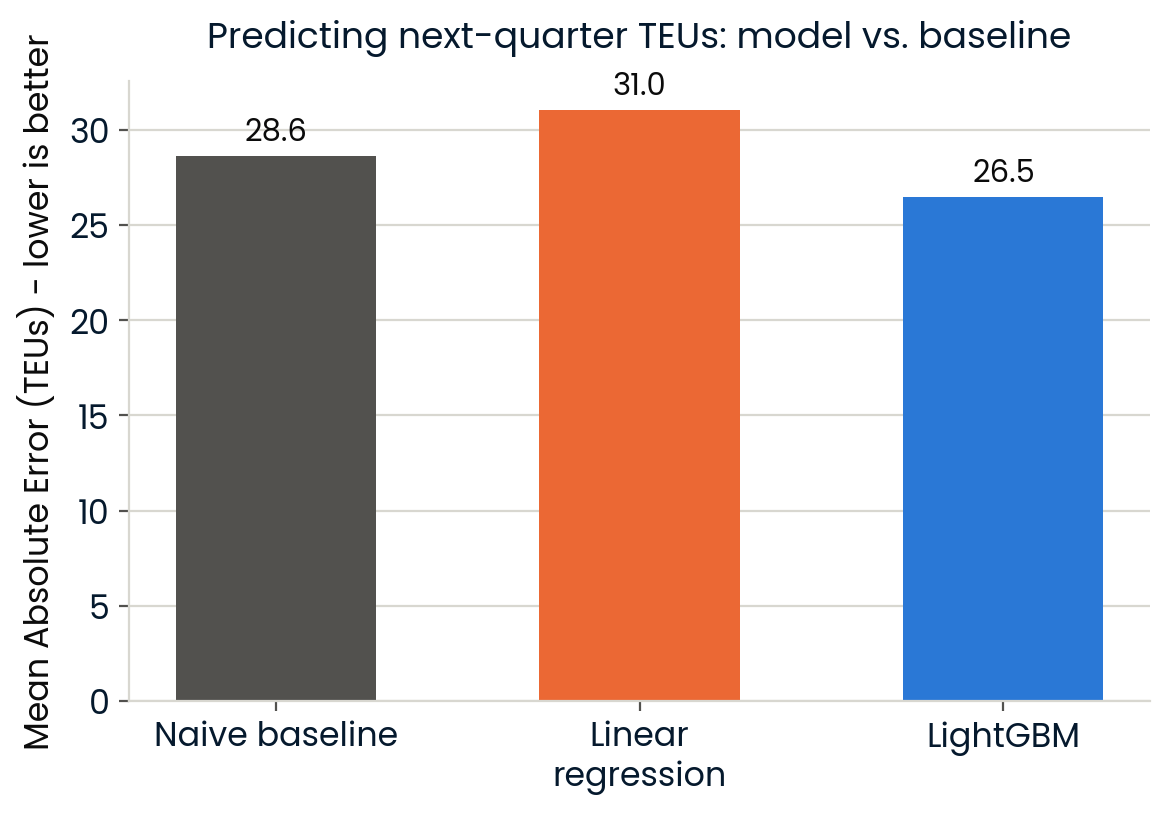

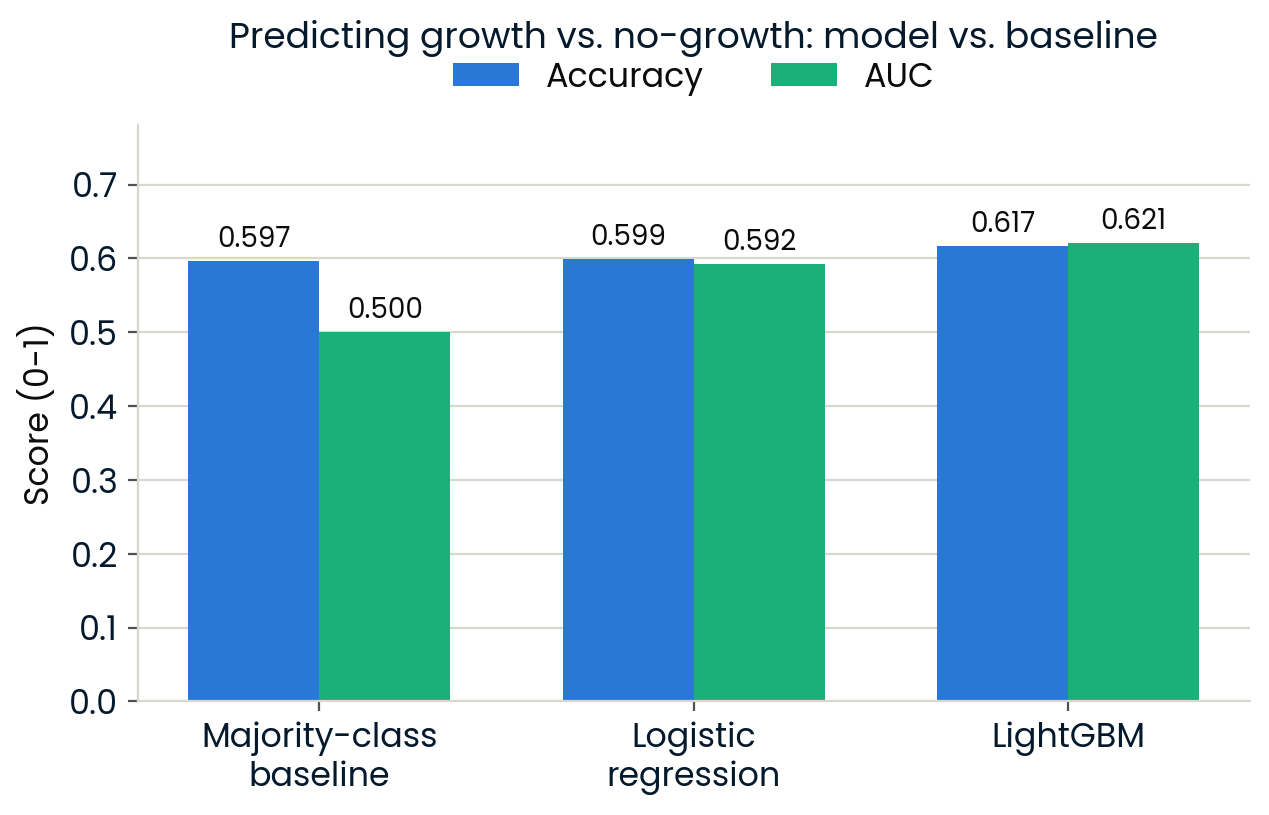

In [8]:
# =============================================================================
# Chart 1 & 2: fully self-contained - no dependency on earlier cells.
# All six numbers below are the final, verified results from your model runs.
# =============================================================================
import matplotlib.pyplot as plt
import numpy as np

BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#d8d7d0"

plt.rcParams.update({
    "font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})

# --- Verified results from your runs -----------------------------------
mae_baseline = 28.645141215240894
mae_linear   = 31.045726465957202
mae_lgbm     = 26.493102117141767

acc_baseline, auc_baseline = 0.5969441947871559, 0.5
acc_logistic, auc_logistic = 0.5987144919247215, 0.5924815606044068
acc_lgbm,     auc_lgbm     = 0.6165808753438462, 0.6208433526948243

# --- Chart 1: MAE comparison (regression task) --------------------------
fig, ax = plt.subplots(figsize=(6, 4.2))
models = ["Naive baseline", "Linear\nregression", "LightGBM"]
maes = [mae_baseline, mae_linear, mae_lgbm]
colors = [MUTED, ORANGE, BLUE]
bars = ax.bar(models, maes, color=colors, width=0.55)
for bar, val in zip(bars, maes):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.4, f"{val:.1f}",
             ha="center", va="bottom", fontsize=11, color=INK)
ax.set_ylabel("Mean Absolute Error (TEUs) - lower is better")
ax.set_title("Predicting next-quarter TEUs: model vs. baseline", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("chart1_mae_comparison.png", dpi=150)
plt.show()


# --- Chart 2: Growth classification - accuracy and AUC side by side -----
fig, ax = plt.subplots(figsize=(6.5, 4.2))
x = np.arange(3)
width = 0.35
acc_vals = [acc_baseline, acc_logistic, acc_lgbm]
auc_vals = [auc_baseline, auc_logistic, auc_lgbm]

bars1 = ax.bar(x - width/2, acc_vals, width, label="Accuracy", color=BLUE)
bars2 = ax.bar(x + width/2, auc_vals, width, label="AUC", color=AQUA)
for bars in (bars1, bars2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f"{h:.3f}",
                 ha="center", va="bottom", fontsize=10, color=INK)

ax.set_xticks(x)
ax.set_xticklabels(["Majority-class\nbaseline", "Logistic\nregression", "LightGBM"])
ax.set_ylabel("Score (0-1)")
ax.set_ylim(0, 0.78)
ax.set_title("Predicting growth vs. no-growth: model vs. baseline", fontsize=13, pad=28)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("chart2_classification_comparison.png", dpi=150)
plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 43.7 MB/s  0:00:00

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
LightGBM MAE: 26.493102117141767


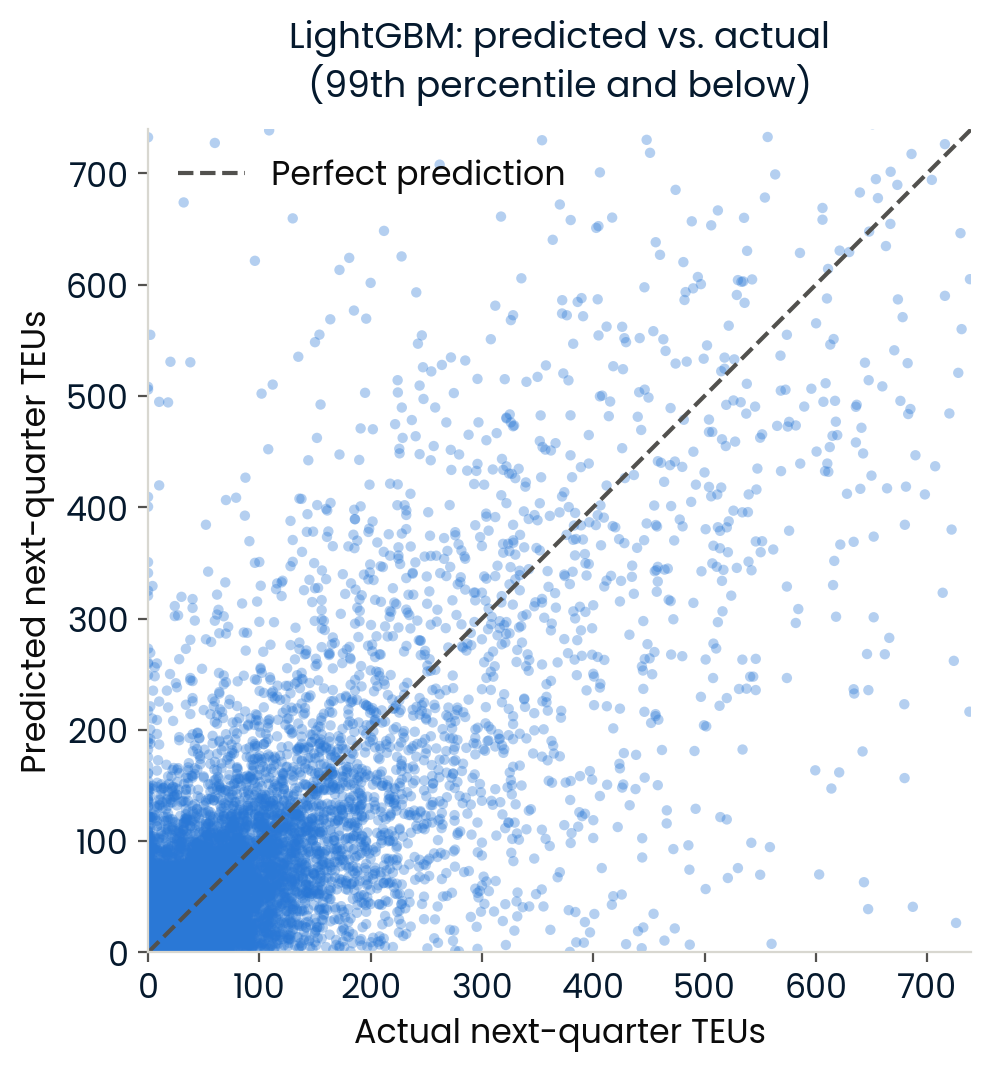

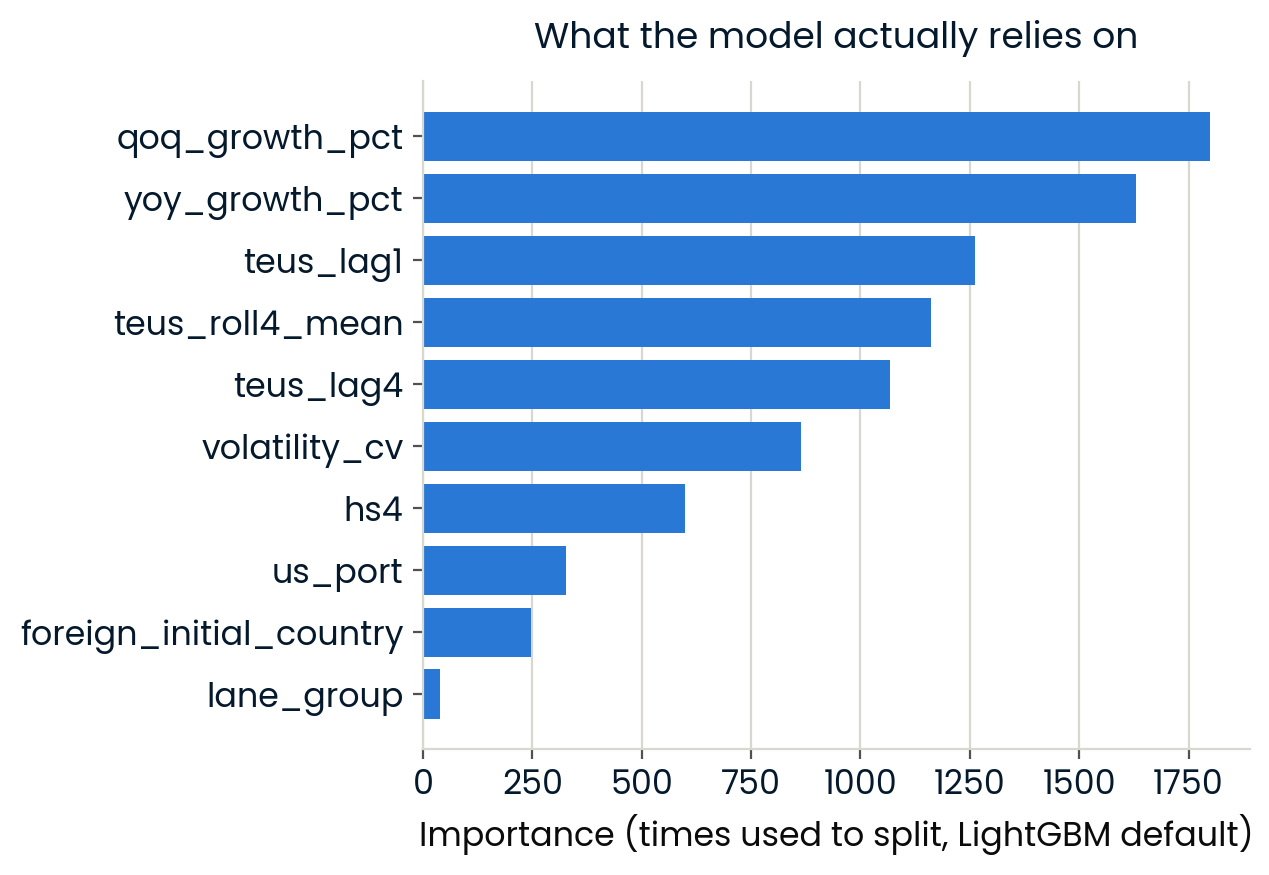

Charts 3 and 4 saved.


In [2]:
# =============================================================================
# Charts 3 & 4 - fully self-contained version.
# Rebuilds everything from the raw CSV: load -> clean -> lanes -> gap-fill ->
# classify -> features -> train LightGBM -> charts. Run as ONE cell, fresh kernel.
# =============================================================================
!pip install lightgbm
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
MUTED = "#52514e"
GRID = "#d8d7d0"
INK = "#0b0b0b"

plt.rcParams.update({
    "font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})

# --- 1. Load + clean --------------------------------------------------------
df = pd.read_csv("JaxPort Data-2021-2025.csv", dtype={"hs4": str})
df = df.drop_duplicates()
df = df[(df["teus"] > 0) & (df["value_usd"] > 0)]
df["hs4_is_chapter_only"] = df["hs4"].astype(str).str.len() == 2

# --- 2. Scope to imports, exclude chapter-only HS4, build lane grain --------
imports = df[df["direction"] == "I"].copy()
imports = imports[~imports["hs4_is_chapter_only"]]
imports["yq"] = imports["year"].astype(str) + "-" + imports["quarter"].astype(str)
all_quarters = [f"{y}-Q{q}" for y in range(2021, 2026) for q in range(1, 5)]

# --- 3. Fill the gaps: complete lane x quarter grid -------------------------
lane_quarter = imports.groupby(
    ["hs4", "foreign_initial_country", "us_port", "yq"], observed=True
)["teus"].sum()
lane_quarter = lane_quarter[lane_quarter > 0]
panel = lane_quarter.unstack("yq", fill_value=0)
panel = panel.reindex(columns=all_quarters, fill_value=0)
panel_long = panel.stack().rename("teus").reset_index()

# --- 4. Classify lanes by forecastability ------------------------------------
n_possible_quarters = panel.shape[1]
lane_stats = pd.DataFrame({
    "total_teus": panel.sum(axis=1),
    "n_quarters_active": (panel > 0).sum(axis=1),
    "mean_teus": panel.mean(axis=1),
    "std_teus": panel.std(axis=1),
})
lane_stats["volatility_cv"] = lane_stats["std_teus"] / lane_stats["mean_teus"].replace(0, np.nan)


def classify_lane(n_quarters, n_possible=n_possible_quarters):
    if n_quarters == n_possible:
        return "Consistent"
    elif n_quarters >= n_possible / 2:
        return "Established"
    elif n_quarters >= 2:
        return "Emerging"
    else:
        return "One-off"


lane_stats["lane_group"] = lane_stats["n_quarters_active"].apply(classify_lane)
forecastable_lane_ids = lane_stats[lane_stats["lane_group"].isin(["Consistent", "Established"])].index

# --- 5. Build lag/rolling features, forecastable lanes only ----------------
panel_long_idx = panel_long.set_index(["hs4", "foreign_initial_country", "us_port"]).index
features = panel_long[panel_long_idx.isin(forecastable_lane_ids)].copy()
features = features.sort_values(["hs4", "foreign_initial_country", "us_port", "yq"])

group_cols = ["hs4", "foreign_initial_country", "us_port"]
grouped = features.groupby(group_cols, observed=True)["teus"]
features["teus_lag1"] = grouped.shift(1)
features["teus_lag4"] = grouped.shift(4)
features["teus_roll4_mean"] = grouped.transform(lambda s: s.shift(1).rolling(4).mean())
features["qoq_growth_pct"] = (features["teus"] - features["teus_lag1"]) / features["teus_lag1"].replace(0, np.nan) * 100
features["yoy_growth_pct"] = (features["teus"] - features["teus_lag4"]) / features["teus_lag4"].replace(0, np.nan) * 100

features_ready = features.dropna(subset=["teus_lag1", "teus_roll4_mean"])

# --- 6. Build the target and train/test split -------------------------------
df_model = features_ready.copy()
df_model["teus_next_q"] = df_model.groupby(group_cols, observed=True)["teus"].shift(-1)
df_model = df_model.dropna(subset=["teus_next_q"])
df_model = df_model.merge(lane_stats[["volatility_cv", "lane_group"]], left_on=group_cols, right_index=True, how="left")

df_model["year"] = df_model["yq"].str[:4].astype(int)
train = df_model[df_model["year"] <= 2024]
test = df_model[df_model["year"] == 2025]

numeric_features = ["teus_lag1", "teus_lag4", "teus_roll4_mean", "qoq_growth_pct", "yoy_growth_pct", "volatility_cv"]
categorical_features = ["hs4", "foreign_initial_country", "us_port", "lane_group"]
feature_cols = numeric_features + categorical_features

for col in categorical_features:
    train[col] = train[col].astype("category")
    test[col] = test[col].astype("category")
    test[col] = test[col].cat.set_categories(train[col].cat.categories)

X_train, X_test = train[feature_cols], test[feature_cols]

# --- 7. Train LightGBM regressor --------------------------------------------
reg_model = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    random_state=42, verbosity=-1
)
reg_model.fit(X_train, train["teus_next_q"], categorical_feature=categorical_features)
y_pred_lgbm = reg_model.predict(X_test)
print("LightGBM MAE:", mean_absolute_error(test["teus_next_q"], y_pred_lgbm))

# --- Chart 3: Predicted vs. actual TEUs (LightGBM regression) ---------------
y_actual = test["teus_next_q"]
cap_val = np.percentile(y_actual, 99)
mask = y_actual <= cap_val

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_actual[mask], y_pred_lgbm[mask], s=14, alpha=0.35, color=BLUE, edgecolors="none")
lims = [0, cap_val]
ax.plot(lims, lims, color=MUTED, linewidth=1.5, linestyle="--", label="Perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual next-quarter TEUs")
ax.set_ylabel("Predicted next-quarter TEUs")
ax.set_title("LightGBM: predicted vs. actual\n(99th percentile and below)", fontsize=13, pad=12)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("chart3_predicted_vs_actual.png", dpi=150)
plt.show()

# --- Chart 4: Feature importance (LightGBM regression) ----------------------
importances = pd.Series(reg_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(importances.index, importances.values, color=BLUE)
ax.set_xlabel("Importance (times used to split, LightGBM default)")
ax.set_title("What the model actually relies on", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("chart4_feature_importance.png", dpi=150)
plt.show()

print("Charts 3 and 4 saved.")

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("JaxPort Data-2021-2025.csv", dtype={"hs4": str})
df = df.drop_duplicates()
df = df[(df["teus"] > 0) & (df["value_usd"] > 0)]
df = df[df["hs4"].str.len() == 4]                      # drop chapter-only HS4
imports = df[df["direction"] == "I"].copy()            # imports only (team decision)
imports["ym"] = pd.to_datetime(dict(year=imports["year"], month=imports["month"], day=1))

all_months = pd.date_range("2021-01-01", "2025-12-01", freq="MS")

monthly = imports.groupby(["us_port", "hs4", "ym"], observed=True)["teus"].sum()
panel = monthly.unstack("ym", fill_value=0).reindex(columns=all_months, fill_value=0)

hs4_desc = imports.drop_duplicates("hs4").set_index("hs4")["hs4_description"]
panel.to_pickle("monthly_panel.pkl")
hs4_desc.to_pickle("hs4_desc.pkl")
print(f"Panel: {panel.shape[0]:,} lanes x {panel.shape[1]} months "
      f"({(panel>0).sum().sum()/panel.size:.1%} of cells have shipments)")

Panel: 18,107 lanes x 60 months (29.1% of cells have shipments)


Lanes total: 18,107 | selected (>= 24/48 train months): 4,330
Share of 2021-24 volume covered: 95.9%
Share of 2025 volume covered:    94.4%


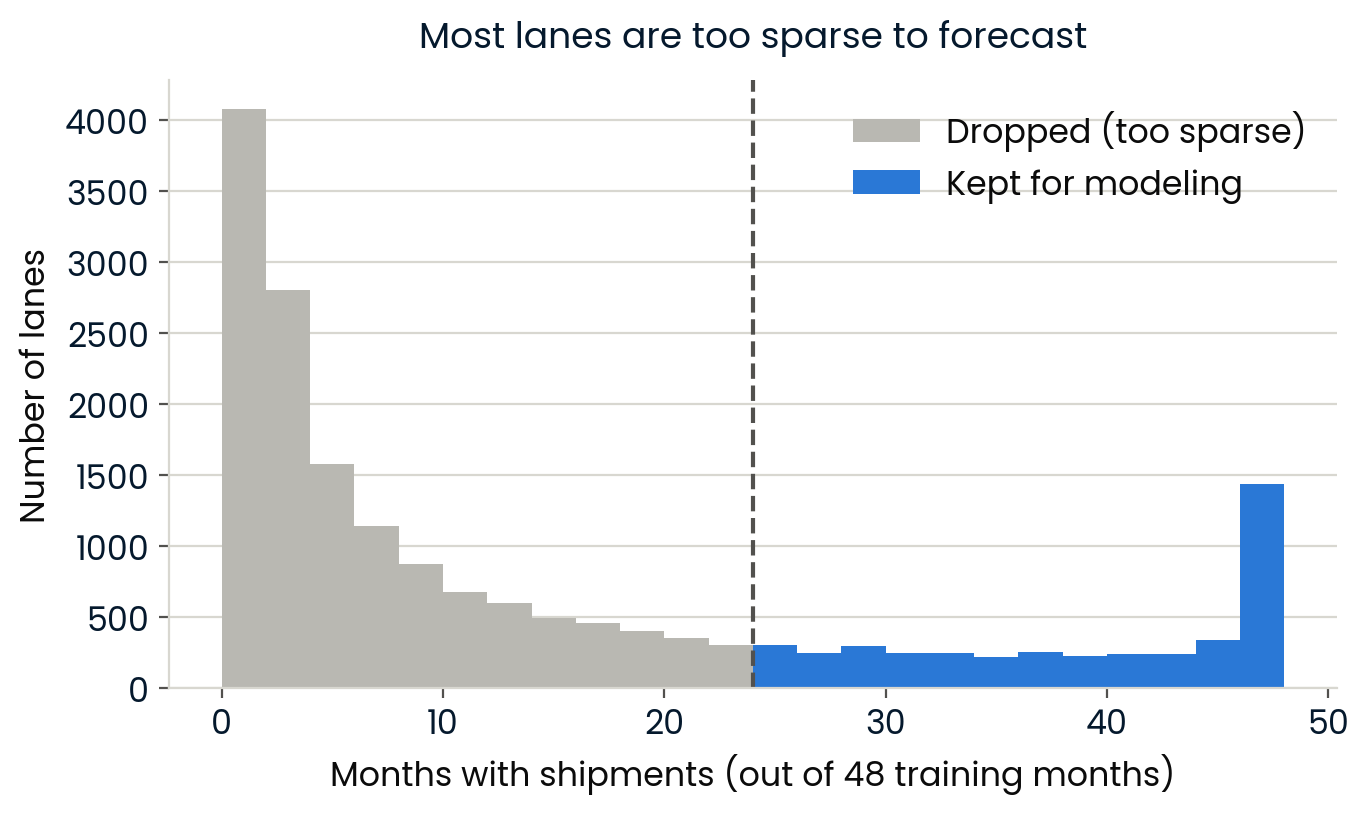

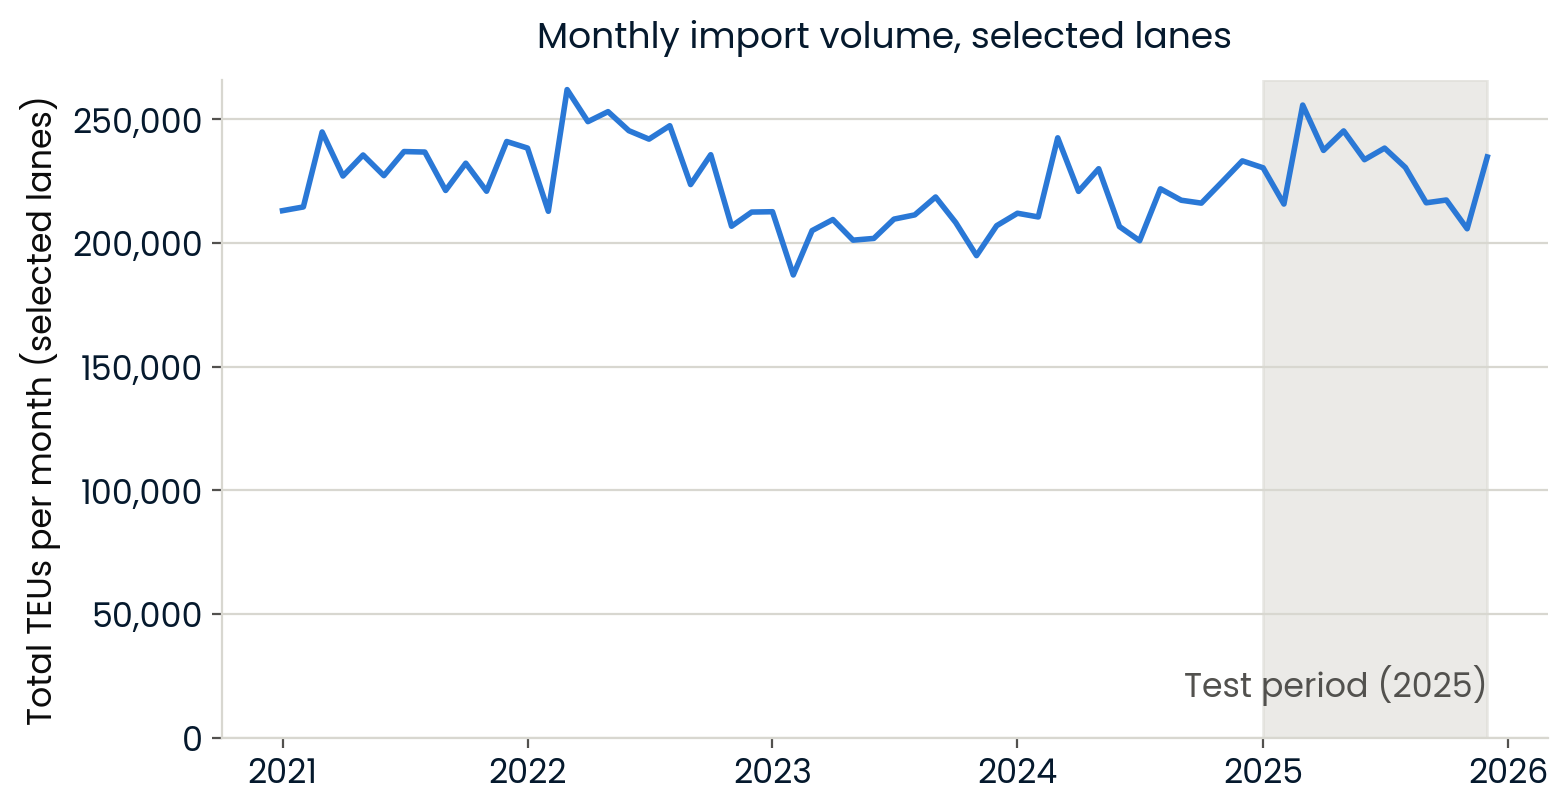

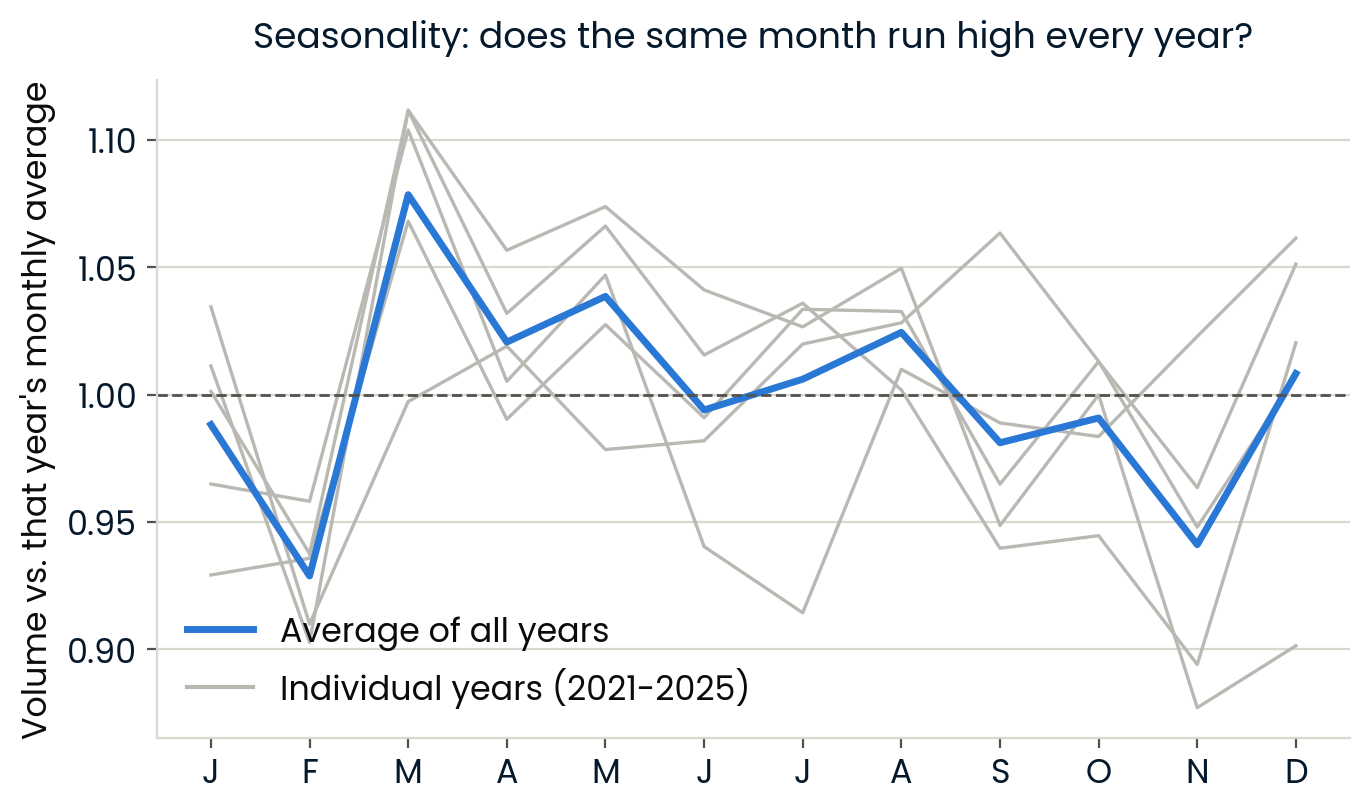

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, MUTED, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#0b0b0b", "#d8d7d0"
GRAY = "#b9b8b2"
plt.rcParams.update({"font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})

panel = pd.read_pickle("monthly_panel.pkl")
TRAIN_END, TEST_START = pd.Timestamp("2024-12-01"), pd.Timestamp("2025-01-01")
MIN_ACTIVE = 24

train = panel.loc[:, :TRAIN_END]
months_active = (train > 0).sum(axis=1)
selected = months_active >= MIN_ACTIVE
sel_lanes = panel.index[selected]
pd.to_pickle(sel_lanes, "selected_lanes.pkl")

print(f"Lanes total: {len(panel):,} | selected (>= {MIN_ACTIVE}/48 train months): {selected.sum():,}")
print(f"Share of 2021-24 volume covered: {train[selected].sum().sum() / train.sum().sum():.1%}")
print(f"Share of 2025 volume covered:    {panel.loc[selected, TEST_START:].sum().sum() / panel.loc[:, TEST_START:].sum().sum():.1%}")

# Figure 1: how many months is each lane active?
fig, ax = plt.subplots(figsize=(7, 4.2))
bins = np.arange(0, 50, 2)
ax.hist(months_active[~selected], bins=bins, color=GRAY, label="Dropped (too sparse)")
ax.hist(months_active[selected], bins=bins, color=BLUE, label="Kept for modeling")
ax.axvline(MIN_ACTIVE, color=MUTED, linestyle="--", linewidth=1.5)
ax.set_xlabel("Months with shipments (out of 48 training months)")
ax.set_ylabel("Number of lanes")
ax.set_title("Most lanes are too sparse to forecast", fontsize=13, pad=12)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("fig1_lane_selection.png", dpi=150); plt.show()

# Figure 2: total monthly TEUs of the selected lanes
total = panel.loc[selected].sum()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(total.index, total.values, color=BLUE, linewidth=2)
ax.axvspan(TEST_START, total.index[-1], color=GRID, alpha=0.5)
ax.text(total.index[-1], total.max() * 0.05, "Test period (2025)", color=MUTED, va="bottom", ha="right")
ax.set_ylim(0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("Total TEUs per month (selected lanes)")
ax.set_title("Monthly import volume, selected lanes", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("fig2_monthly_total.png", dpi=150); plt.show()

# Figure 3: is there a yearly seasonal pattern?
by_year = total.groupby(total.index.year)
fig, ax = plt.subplots(figsize=(7, 4.2))
profiles = []
for yr, s in by_year:
    idx = (s / s.mean()).values
    profiles.append(idx)
    ax.plot(range(1, 13), idx, color=GRAY, linewidth=1.2)
ax.plot(range(1, 13), np.mean(profiles, axis=0), color=BLUE, linewidth=2.5, label="Average of all years")
ax.plot([], [], color=GRAY, label="Individual years (2021-2025)")
ax.axhline(1, color=MUTED, linestyle="--", linewidth=1)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("Volume vs. that year's monthly average")
ax.set_title("Seasonality: does the same month run high every year?", fontsize=13, pad=12)
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("fig3_seasonality.png", dpi=150); plt.show()

In [9]:
import pandas as pd
import numpy as np

TRAIN_END = pd.Timestamp("2024-12-01")
TEST_START = pd.Timestamp("2025-01-01")


def load_data():
    """Monthly panel restricted to the selected lanes (lanes x 60 months)."""
    panel = pd.read_pickle("monthly_panel.pkl")
    lanes = pd.read_pickle("selected_lanes.pkl")
    return panel.loc[lanes]


def to_quarters(monthly):
    """Sum a lanes x months table into lanes x quarters."""
    q = monthly.copy()
    q.columns = pd.PeriodIndex(q.columns, freq="M").asfreq("Q")
    return q.T.groupby(level=0).sum().T


def score_quarterly(pred_monthly, panel, name="model"):
    """pred_monthly: lanes x 12 table of predicted TEUs for the 2025 months."""
    actual_m = panel.loc[:, TEST_START:]
    pred_m = pred_monthly.reindex(index=actual_m.index, columns=actual_m.columns)
    actual_q, pred_q = to_quarters(actual_m), to_quarters(pred_m)
    err = (pred_q - actual_q).abs()
    return {
        "model": name,
        "quarterly_MAE": err.values.mean(),
        "quarterly_WAPE_%": err.values.sum() / actual_q.values.sum() * 100,
        "volume_bias_%": (pred_q.values.sum() / actual_q.values.sum() - 1) * 100,
    }


def naive_last_month(panel):
    """Baseline 1: next month = this month."""
    return panel.shift(1, axis=1).loc[:, TEST_START:]


def naive_seasonal(panel):
    """Baseline 2: next month = same month last year."""
    return panel.shift(12, axis=1).loc[:, TEST_START:]



In [11]:
%%writefile eval_utils.py
import pandas as pd
import numpy as np

TRAIN_END = pd.Timestamp("2024-12-01")
TEST_START = pd.Timestamp("2025-01-01")


def load_data():
    """Monthly panel restricted to the selected lanes (lanes x 60 months)."""
    panel = pd.read_pickle("monthly_panel.pkl")
    lanes = pd.read_pickle("selected_lanes.pkl")
    return panel.loc[lanes]


def to_quarters(monthly):
    """Sum a lanes x months table into lanes x quarters."""
    q = monthly.copy()
    q.columns = pd.PeriodIndex(q.columns, freq="M").asfreq("Q")
    return q.T.groupby(level=0).sum().T


def score_quarterly(pred_monthly, panel, name="model"):
    """pred_monthly: lanes x 12 table of predicted TEUs for the 2025 months."""
    actual_m = panel.loc[:, TEST_START:]
    pred_m = pred_monthly.reindex(index=actual_m.index, columns=actual_m.columns)
    actual_q, pred_q = to_quarters(actual_m), to_quarters(pred_m)
    err = (pred_q - actual_q).abs()
    return {
        "model": name,
        "quarterly_MAE": err.values.mean(),
        "quarterly_WAPE_%": err.values.sum() / actual_q.values.sum() * 100,
        "volume_bias_%": (pred_q.values.sum() / actual_q.values.sum() - 1) * 100,
    }


def naive_last_month(panel):
    """Baseline 1: next month = this month."""
    return panel.shift(1, axis=1).loc[:, TEST_START:]


def naive_seasonal(panel):
    """Baseline 2: next month = same month last year."""
    return panel.shift(12, axis=1).loc[:, TEST_START:]

Writing eval_utils.py


                             quarterly_MAE  quarterly_WAPE_%  volume_bias_%
model                                                                      
Naive: last month                    26.53             16.64          -0.06
Naive: same month last year          67.16             42.13          -4.51


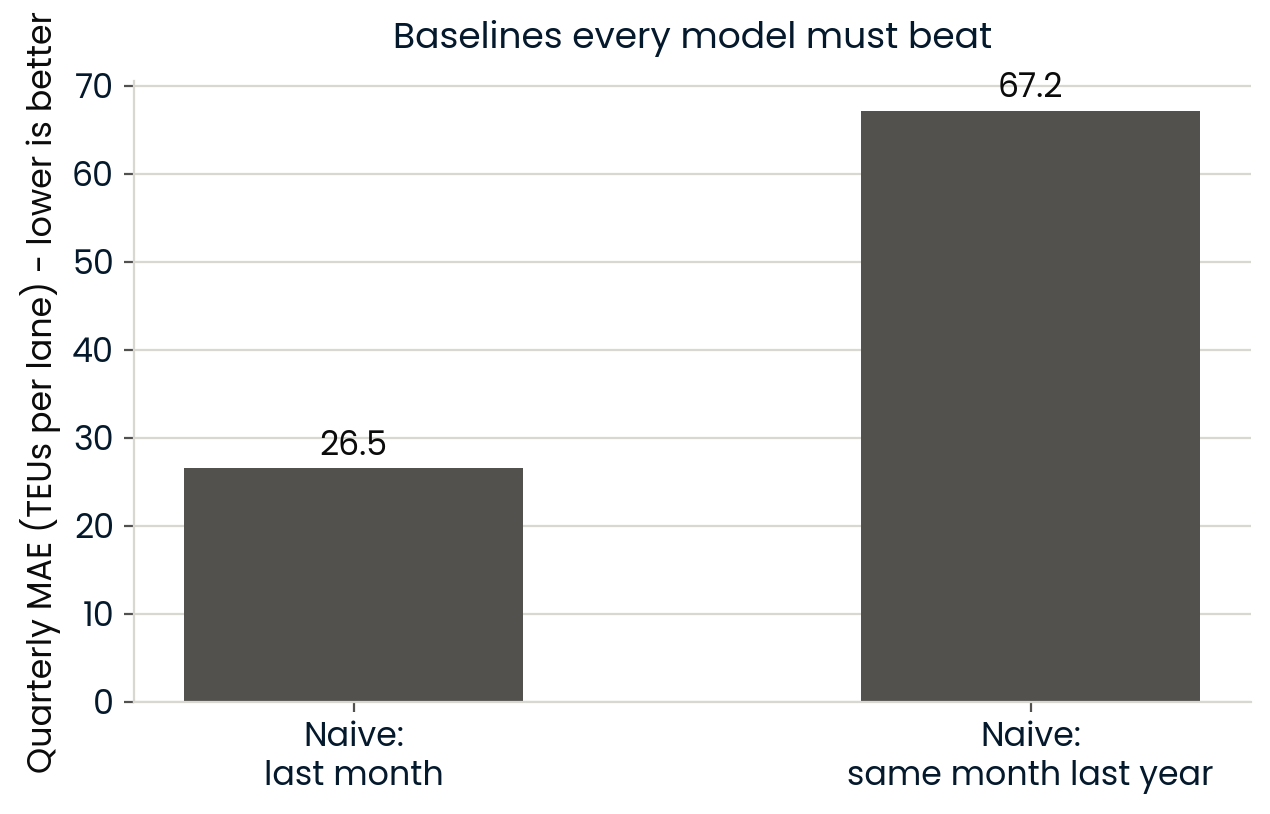

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from eval_utils import load_data, score_quarterly, naive_last_month, naive_seasonal

BLUE, ORANGE, MUTED, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#0b0b0b", "#d8d7d0"
plt.rcParams.update({"font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})

panel = load_data()
results = pd.DataFrame([
    score_quarterly(naive_last_month(panel), panel, "Naive: last month"),
    score_quarterly(naive_seasonal(panel), panel, "Naive: same month last year"),
]).set_index("model")
print(results.round(2))
results.to_csv("results_baselines.csv")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar([n.replace(": ", ":\n") for n in results.index], results["quarterly_MAE"], color=MUTED, width=0.5)
for b, v in zip(bars, results["quarterly_MAE"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}", ha="center", va="bottom", color=INK)
ax.set_ylabel("Quarterly MAE (TEUs per lane) - lower is better")
ax.set_title("Baselines every model must beat", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("fig4_baselines.png", dpi=150); plt.show()

In [1]:
import pandas as pd
import numpy as np

DROP_SEGMENTS = ["Lumpy", "Sporadic"]     # <- change this list to keep/drop other groups
TRAIN_END = pd.Timestamp("2024-12-01")

panel = pd.read_pickle("monthly_panel.pkl")          # lanes (us_port, hs4) x 60 months
hs4_desc = pd.read_pickle("hs4_desc.pkl")
train = panel.loc[:, :TRAIN_END]

# ADI = avg gap between shipping months; CV2 = variability of shipment size
n_active = (train > 0).sum(axis=1)
nz = train.where(train > 0)
adi = train.shape[1] / n_active.replace(0, np.nan)
cv2 = (nz.std(axis=1, ddof=0) / nz.mean(axis=1)) ** 2

seg = pd.Series("Sporadic", index=train.index)
ok = n_active >= 12
seg[ok & (adi < 1.32) & (cv2 < 0.49)] = "Smooth"
seg[ok & (adi < 1.32) & (cv2 >= 0.49)] = "Erratic"
seg[ok & (adi >= 1.32) & (cv2 < 0.49)] = "Intermittent"
seg[ok & (adi >= 1.32) & (cv2 >= 0.49)] = "Lumpy"

# Summary of what each group is
vol_train = train.sum(axis=1)
vol_test = panel.loc[:, "2025-01-01":].sum(axis=1)
summary = pd.DataFrame({
    "lanes": seg.value_counts(),
    "% of 2021-24 volume": vol_train.groupby(seg).sum() / vol_train.sum() * 100,
    "% of 2025 volume": vol_test.groupby(seg).sum() / vol_test.sum() * 100,
}).loc[["Smooth", "Erratic", "Intermittent", "Lumpy", "Sporadic"]]
print(summary.round(1))

# Save EVERYTHING with its label first (nothing removed)
def to_long(p, seg_labels):
    out = p.stack().rename("teus").reset_index()
    out.columns = ["us_port", "hs4", "month", "teus"]
    out["hs4_description"] = out["hs4"].map(hs4_desc)
    out["segment"] = pd.MultiIndex.from_frame(out[["us_port", "hs4"]]).map(seg_labels)
    out["year"], out["month_num"] = out["month"].dt.year, out["month"].dt.month
    return out[["us_port", "hs4", "hs4_description", "segment", "month", "year", "month_num", "teus"]]

seg.to_pickle("lane_segments.pkl")
to_long(panel, seg).to_csv("lanes_monthly_ALL_with_segment.csv", index=False)

# Drop the unwanted groups and save the MODELING dataset
keep = seg[~seg.isin(DROP_SEGMENTS)]
model_panel = panel.loc[keep.index]
model_panel.to_pickle("modeling_panel.pkl")                  # wide: lanes x 60 months
modeling_long = to_long(model_panel, keep)
modeling_long.to_csv("modeling_dataset.csv", index=False)    # long: one row per lane-month

print(f"\nDropped groups: {DROP_SEGMENTS}")
print(f"Modeling dataset: {len(keep):,} lanes x {model_panel.shape[1]} months = {len(modeling_long):,} rows")
print(f"  covers {vol_train[keep.index].sum()/vol_train.sum():.1%} of 2021-24 volume and "
      f"{vol_test[keep.index].sum()/vol_test.sum():.1%} of 2025 volume")

              lanes  % of 2021-24 volume  % of 2025 volume
Smooth         1143                 66.2              64.7
Erratic        1475                 23.0              23.3
Intermittent   1187                  2.6               2.0
Lumpy          3144                  6.8               7.6
Sporadic      11158                  1.4               2.4

Dropped groups: ['Lumpy', 'Sporadic']
Modeling dataset: 3,805 lanes x 60 months = 228,300 rows
  covers 91.8% of 2021-24 volume and 90.1% of 2025 volume


In [1]:
%%writefile eval_utils.py
import pandas as pd
import numpy as np
import re

TRAIN_END = pd.Timestamp("2024-12-01")
TEST_START = pd.Timestamp("2025-01-01")
SEGMENTS = ["Smooth", "Erratic", "Intermittent"]


def load_data():
    """The modeling panel: lanes x 60 months (Lumpy + Sporadic lanes already removed)."""
    return pd.read_pickle("modeling_panel.pkl")


def load_segments():
    """Segment label (Smooth / Erratic / Intermittent) for each lane in the modeling panel."""
    return pd.read_pickle("lane_segments.pkl").loc[load_data().index]


def to_quarters(monthly):
    """Sum a lanes x months table into lanes x quarters."""
    q = monthly.copy()
    q.columns = pd.PeriodIndex(q.columns, freq="M").asfreq("Q")
    return q.T.groupby(level=0).sum().T


def score_quarterly(pred_monthly, panel, name="model"):
    """pred_monthly: lanes x 12 table of predicted TEUs for the 2025 months."""
    actual_m = panel.loc[:, TEST_START:]
    pred_m = pred_monthly.reindex(index=actual_m.index, columns=actual_m.columns)
    actual_q, pred_q = to_quarters(actual_m), to_quarters(pred_m)
    err = (pred_q - actual_q).abs()
    return {
        "model": name,
        "quarterly_MAE": err.values.mean(),
        "quarterly_WAPE_%": err.values.sum() / actual_q.values.sum() * 100,
        "volume_bias_%": (pred_q.values.sum() / actual_q.values.sum() - 1) * 100,
    }


def naive_last_month(panel):
    """Baseline 1: next month = this month."""
    return panel.shift(1, axis=1).loc[:, TEST_START:]


def naive_seasonal(panel):
    """Baseline 2: next month = same month last year."""
    return panel.shift(12, axis=1).loc[:, TEST_START:]


def record(name, pred_monthly, panel=None, seg=None):
    """Score a model overall AND by lane group, save its predictions, and add it to
    results_all.csv (replacing any earlier row with the same name)."""
    panel = load_data() if panel is None else panel
    seg = load_segments() if seg is None else seg
    row = score_quarterly(pred_monthly, panel, name)
    for s in SEGMENTS:
        lanes = seg.index[seg == s]
        row[f"WAPE_{s}"] = score_quarterly(pred_monthly.loc[lanes], panel.loc[lanes], name)["quarterly_WAPE_%"]
    pred_monthly.to_pickle("pred_" + re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_") + ".pkl")
    try:
        res = pd.read_csv("results_all.csv", index_col="model")
    except FileNotFoundError:
        res = pd.DataFrame()
    res.loc[name, list(row.keys())[1:]] = list(row.values())[1:]
    res.index.name = "model"
    res.to_csv("results_all.csv")
    return res

Overwriting eval_utils.py


3,805 lanes | Smooth: 1,143 | Erratic: 1,475 | Intermittent: 1,187
SARIMA done in 874s
                             quarterly_MAE  quarterly_WAPE_%  volume_bias_%  WAPE_Smooth  WAPE_Erratic  WAPE_Intermittent
model                                                                                                                    
Naive: last month                    27.14             15.69           0.04        10.87         27.44              34.62
Naive: same month last year          68.52             39.61          -4.40        30.93         59.32              90.44
SARIMA                               36.64             21.18          -0.18        16.87         30.68              49.72


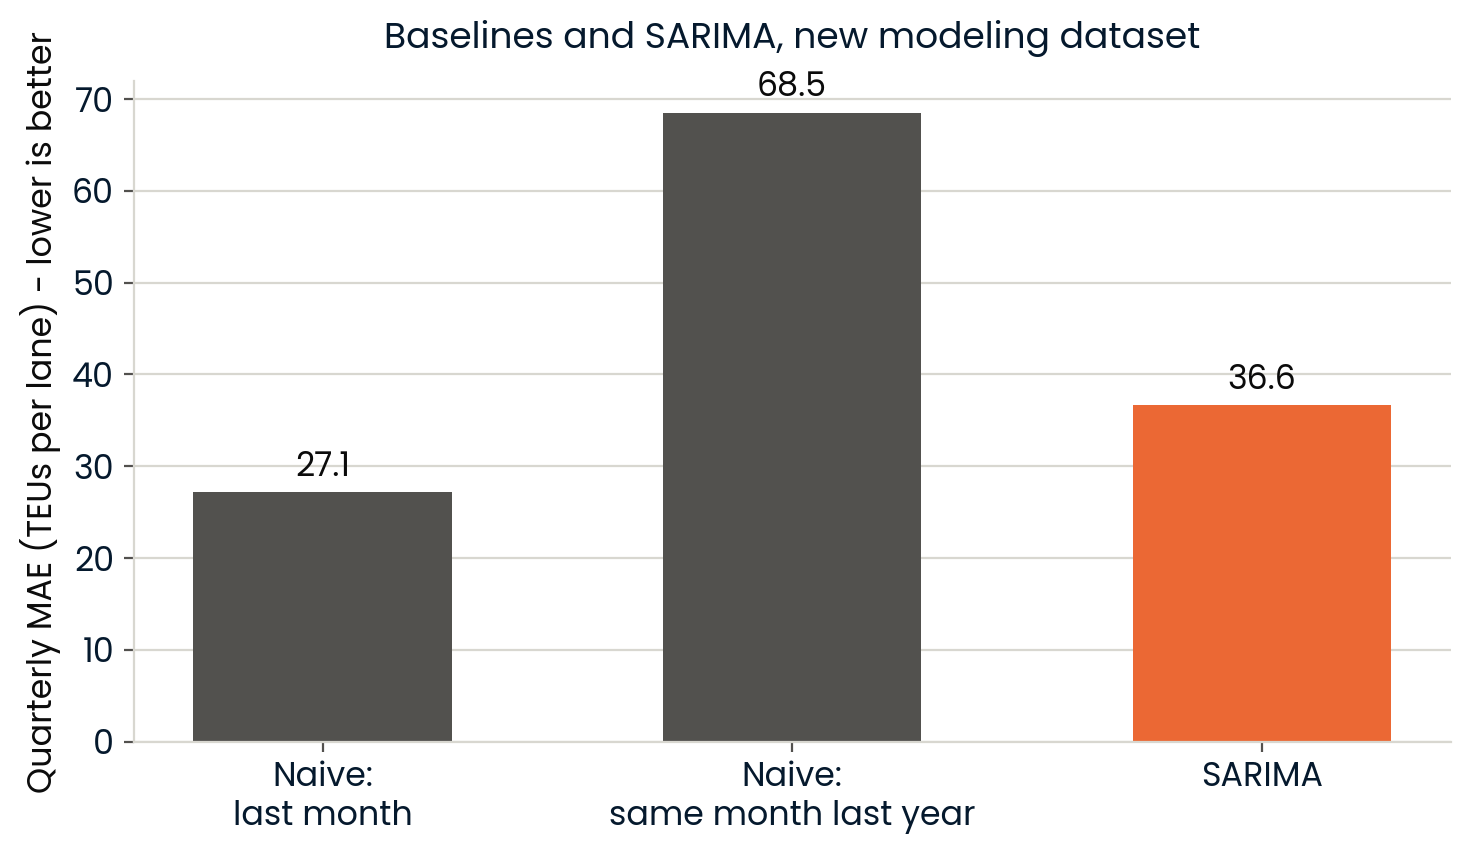

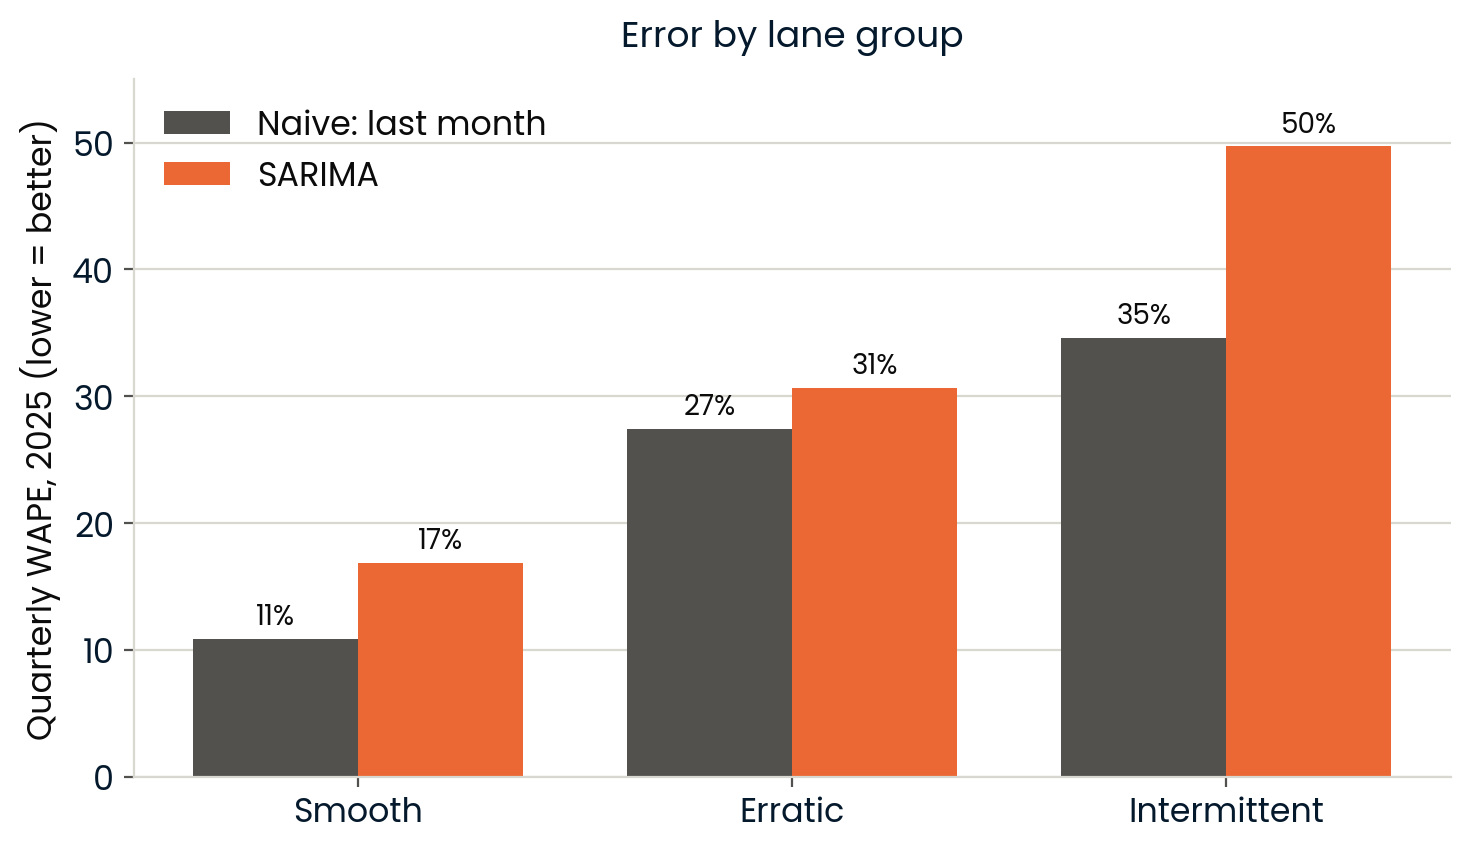

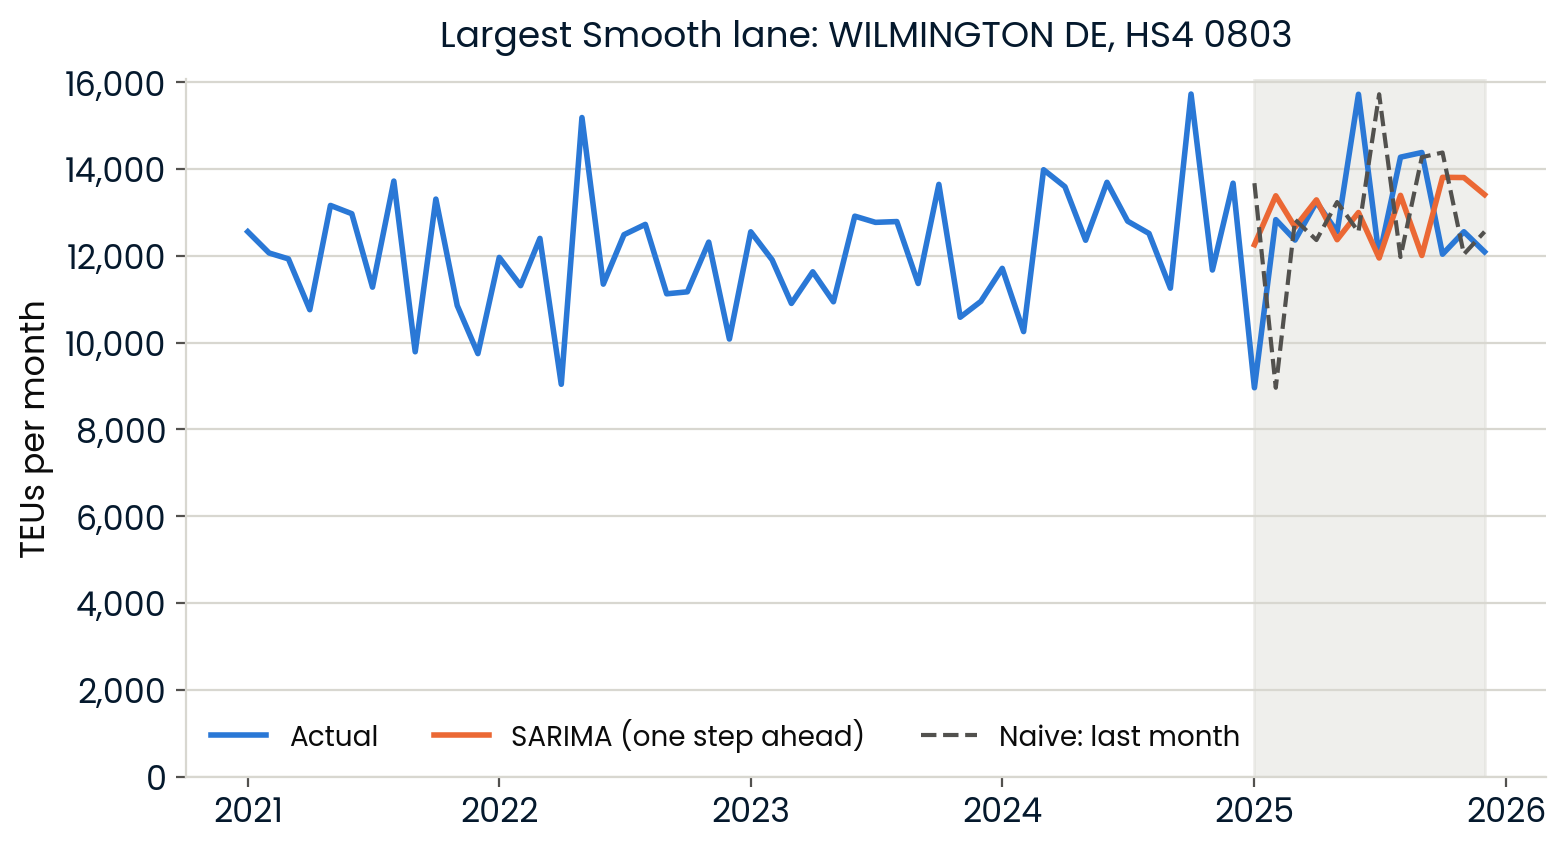

In [2]:
import os, warnings, time
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from eval_utils import *

warnings.filterwarnings("ignore")
if os.path.exists("results_all.csv"):
    os.remove("results_all.csv")                       # start clean on the new dataset

BLUE, ORANGE, AQUA, MUTED, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#0b0b0b", "#d8d7d0"
plt.rcParams.update({"font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})

panel, seg = load_data(), load_segments()
print(f"{panel.shape[0]:,} lanes | " + " | ".join(f"{s}: {(seg==s).sum():,}" for s in SEGMENTS))

# Baselines
record("Naive: last month", naive_last_month(panel), panel, seg)
record("Naive: same month last year", naive_seasonal(panel), panel, seg)

# SARIMA
test_cols, preds, t0 = panel.loc[:, TEST_START:].columns, {}, time.time()
for lane, row in panel.iterrows():
    y = row.loc[:TRAIN_END].astype(float).values
    try:
        fit = SARIMAX(y, order=(1, 1, 1), seasonal_order=(1, 0, 0, 12),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100)
        p = fit.append(row.loc[TEST_START:].astype(float).values, refit=False).get_prediction(start=len(y)).predicted_mean
        preds[lane] = np.clip(p, 0, None)
    except Exception:
        preds[lane] = row.shift(1).loc[TEST_START:].values
pred_sarima = pd.DataFrame(preds, index=test_cols).T
print(f"SARIMA done in {time.time()-t0:.0f}s")
res = record("SARIMA", pred_sarima, panel, seg)
print(res.round(2).to_string())

# Figure A1: overall comparison
fig, ax = plt.subplots(figsize=(7.5, 4.4))
names = [n.replace(": ", ":\n") for n in res.index]
bars = ax.bar(names, res["quarterly_MAE"], color=[MUTED, MUTED, ORANGE], width=0.55)
for b, v in zip(bars, res["quarterly_MAE"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.8, f"{v:.1f}", ha="center", va="bottom")
ax.set_ylabel("Quarterly MAE (TEUs per lane) - lower is better")
ax.set_title("Baselines and SARIMA, new modeling dataset", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figA1_overall.png", dpi=150); plt.show()

# Figure A2: by lane group
x = np.arange(len(SEGMENTS)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for i, (nm, col) in enumerate([("Naive: last month", MUTED), ("SARIMA", ORANGE)]):
    vals = [res.loc[nm, f"WAPE_{s}"] for s in SEGMENTS]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, color=col, label=nm)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.6, f"{v:.0f}%", ha="center", va="bottom", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(SEGMENTS)
ax.set_ylabel("Quarterly WAPE, 2025 (lower = better)"); ax.set_ylim(0, 55)
ax.set_title("Error by lane group", fontsize=13, pad=12)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figA2_by_segment.png", dpi=150); plt.show()

# Figure A3: the largest Smooth lane, actual vs predicted (monthly)
lane = (seg == "Smooth").pipe(lambda m: panel.loc[m[m].index].sum(axis=1).idxmax())
hist = panel.loc[lane]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(hist.index, hist.values, color=BLUE, linewidth=2, label="Actual")
ax.plot(pred_sarima.columns, pred_sarima.loc[lane].values, color=ORANGE, linewidth=2, label="SARIMA (one step ahead)")
ax.plot(pred_sarima.columns, naive_last_month(panel).loc[lane].values, color=MUTED, linewidth=1.5, linestyle="--", label="Naive: last month")
ax.axvspan(TEST_START, hist.index[-1], color=GRID, alpha=0.4)
ax.set_ylim(0); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("TEUs per month")
ax.set_title(f"Largest Smooth lane: {lane[0]}, HS4 {lane[1]}", fontsize=13, pad=12)
ax.legend(frameon=False, loc="lower left", ncol=3, fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figA3_example_lane.png", dpi=150); plt.show()

In [1]:
%%writefile -a eval_utils.py


from sklearn.metrics import roc_auc_score, accuracy_score

COLORS = {"Naive: last month": "#52514e", "Naive: same month last year": "#b9b8b2",
          "SARIMA": "#eb6834", "Linear regression": "#1baf7a", "Random Forest": "#eda100",
          "XGBoost": "#2a78d6", "LSTM": "#e87ba4", "N-HiTS": "#4a3aa7"}


def build_features(panel=None, seg=None):
    """One row per lane-month with only PAST information (nothing from the month itself):
    lag1/2/3/12, rolling means of the previous 3/6/12 months, the lane's 2021-24 average
    TEUs (lane_mean), the lane group, and the calendar month. y = this month's TEUs;
    grew = 1 if y > lag1 (only meaningful when lag1 > 0)."""
    panel = load_data() if panel is None else panel
    seg = load_segments() if seg is None else seg
    tr_cols = panel.columns[panel.columns <= TRAIN_END]
    long = panel.reset_index().melt(id_vars=["us_port", "hs4"], var_name="month", value_name="y")
    long["month"] = pd.to_datetime(long["month"])
    long = long.sort_values(["us_port", "hs4", "month"]).reset_index(drop=True)
    g = long.groupby(["us_port", "hs4"], sort=False)["y"]
    for k in (1, 2, 3, 12):
        long[f"lag{k}"] = g.shift(k)
    for k in (3, 6, 12):
        long[f"roll{k}"] = g.transform(lambda s, k=k: s.shift(1).rolling(k).mean())
    lane_mean = panel[tr_cols].mean(axis=1).rename("lane_mean").reset_index()
    long = long.merge(lane_mean, on=["us_port", "hs4"])
    long["segment"] = pd.MultiIndex.from_frame(long[["us_port", "hs4"]]).map(seg)
    long["month_num"] = long["month"].dt.month
    long["grew"] = (long["y"] > long["lag1"]).astype(int)
    return long


def split(long, needed):
    """Time split: train = through Dec 2024, test = 2025. Drops rows missing any column in `needed`."""
    d = long.dropna(subset=needed)
    return d[d["month"] <= TRAIN_END].copy(), d[d["month"] >= TEST_START].copy()


def to_panel(test_rows, pred):
    """Turn predictions for test rows back into a lanes x 12-months table (negatives clipped to 0)."""
    d = test_rows.assign(p=np.clip(np.asarray(pred, dtype=float), 0, None))
    return d.pivot(index=["us_port", "hs4"], columns="month", values="p")


def record_clf(name, test_rows, proba):
    """Score a growth classifier on 2025 lane-months where the lane shipped last month
    (lag1 > 0): accuracy vs always-guess-the-majority, and AUC. Overall + by lane group."""
    d = test_rows[test_rows["lag1"] > 0].copy()
    d["p"] = pd.Series(np.asarray(proba), index=test_rows.index)[d.index]
    rows = {}
    for label, sub in [("All", d)] + [(s, d[d["segment"] == s]) for s in SEGMENTS]:
        base = max(sub["grew"].mean(), 1 - sub["grew"].mean())
        rows[label] = {"accuracy": accuracy_score(sub["grew"], sub["p"] > 0.5),
                       "majority_baseline": base, "AUC": roc_auc_score(sub["grew"], sub["p"]),
                       "n_rows": len(sub)}
    out = pd.DataFrame(rows).T
    out.insert(0, "model", name)
    out.index.name = "group"
    out = out.reset_index()
    try:
        old = pd.read_csv("results_classification.csv")
        out_all = pd.concat([old[old["model"] != name], out])
    except FileNotFoundError:
        out_all = out
    out_all.to_csv("results_classification.csv", index=False)
    return out.set_index("group").drop(columns="model")

Appending to eval_utils.py


Train rows: 159,810 | Test rows: 45,660

Linear regression coefficients:
           Smooth  Erratic  Intermittent
lag1        0.150    0.869         0.708
lag2        0.232   -0.194        -0.015
lag3        0.118   -0.003         0.096
roll3       0.167    0.224         0.263
roll6      -0.134   -0.570        -0.688
lane_mean   0.468    0.680         0.655

Regression results (quarterly, 2025):
                             quarterly_MAE  quarterly_WAPE_%  volume_bias_%  WAPE_Smooth  WAPE_Erratic  WAPE_Intermittent
model                                                                                                                    
Naive: last month                    27.14             15.69           0.04        10.87         27.44              34.62
Naive: same month last year          68.52             39.61          -4.40        30.93         59.32              90.44
SARIMA                               36.64             21.18          -0.18        16.87         30.68           

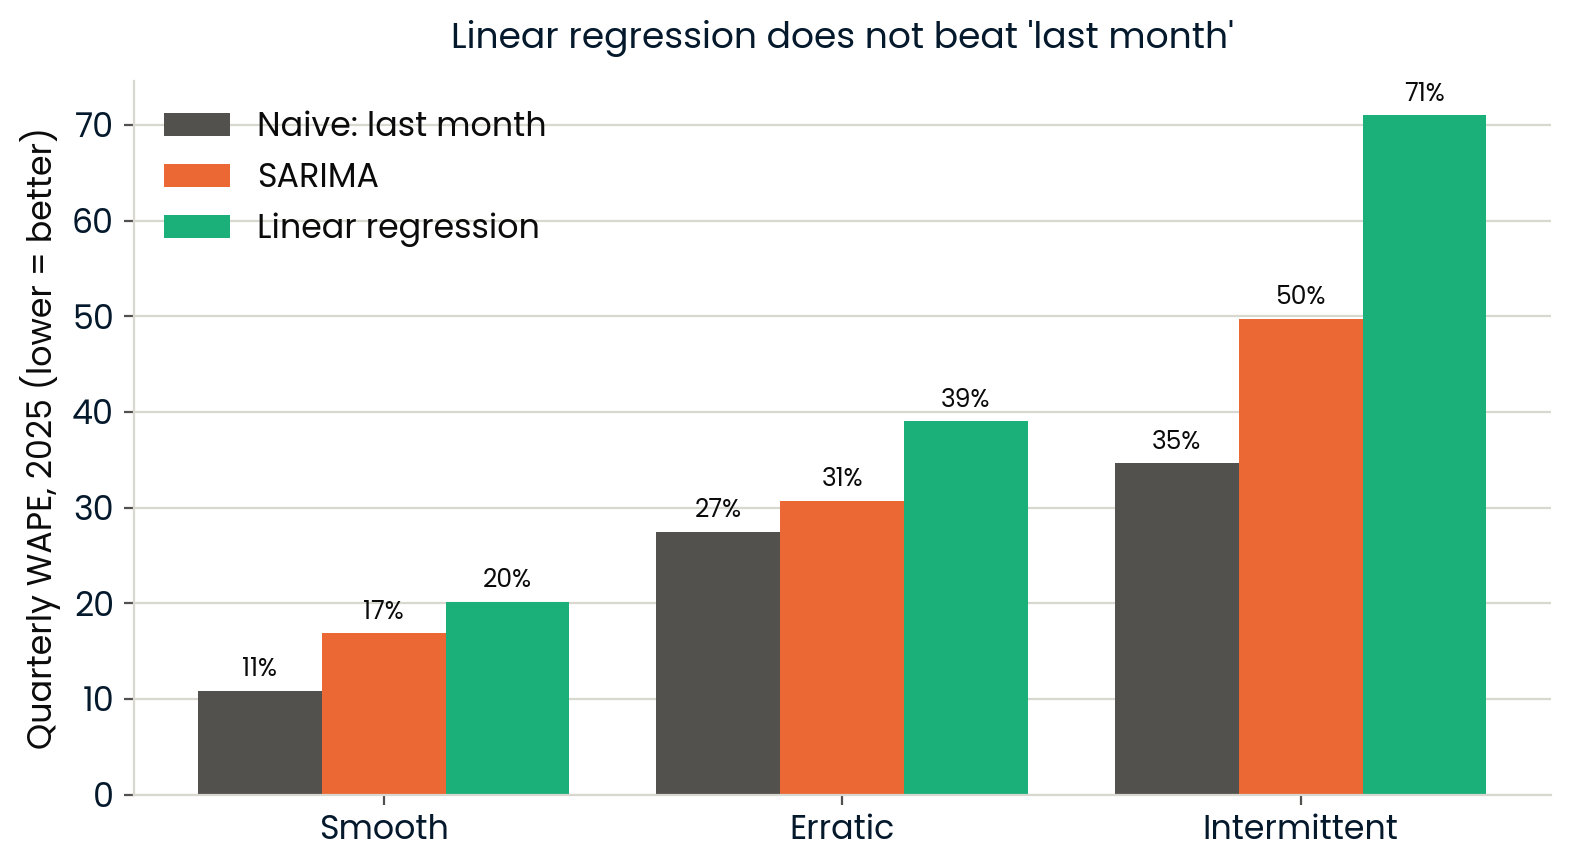

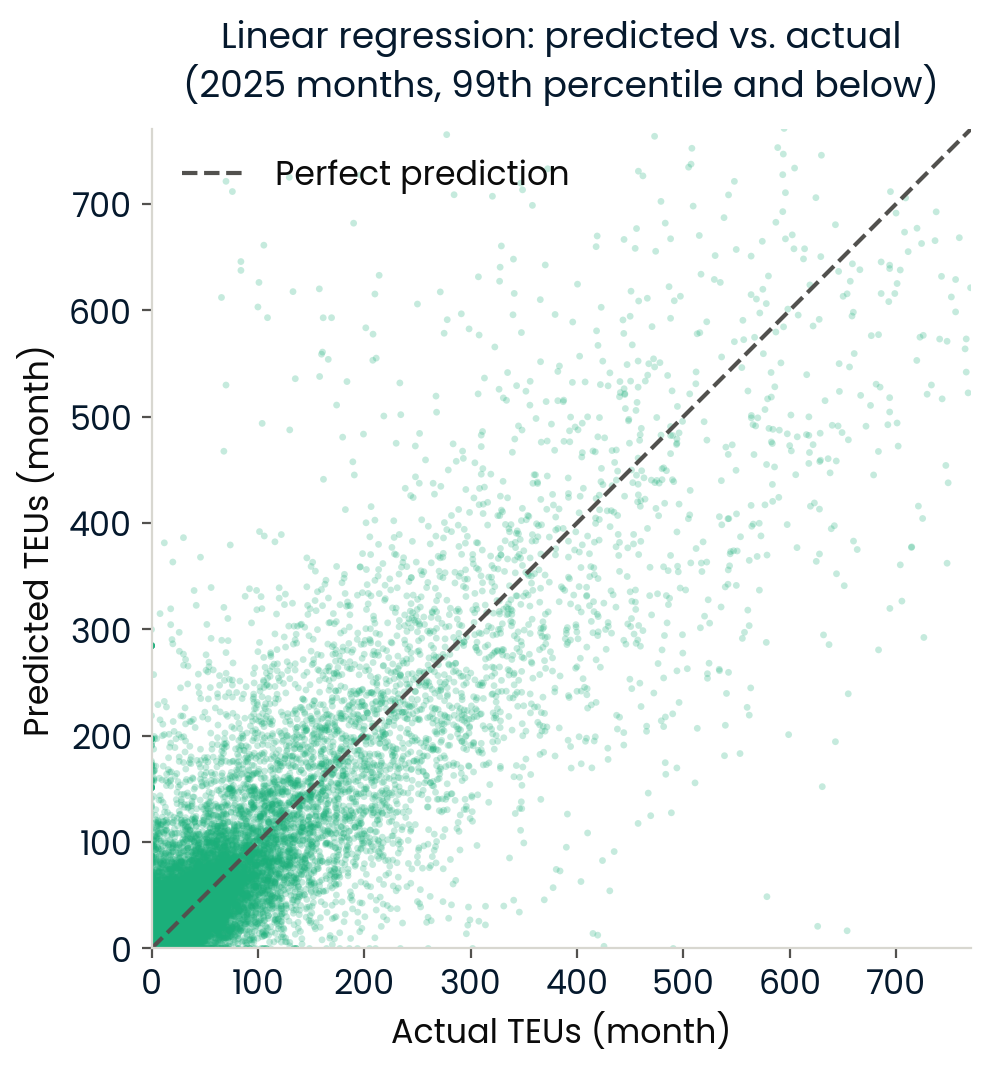

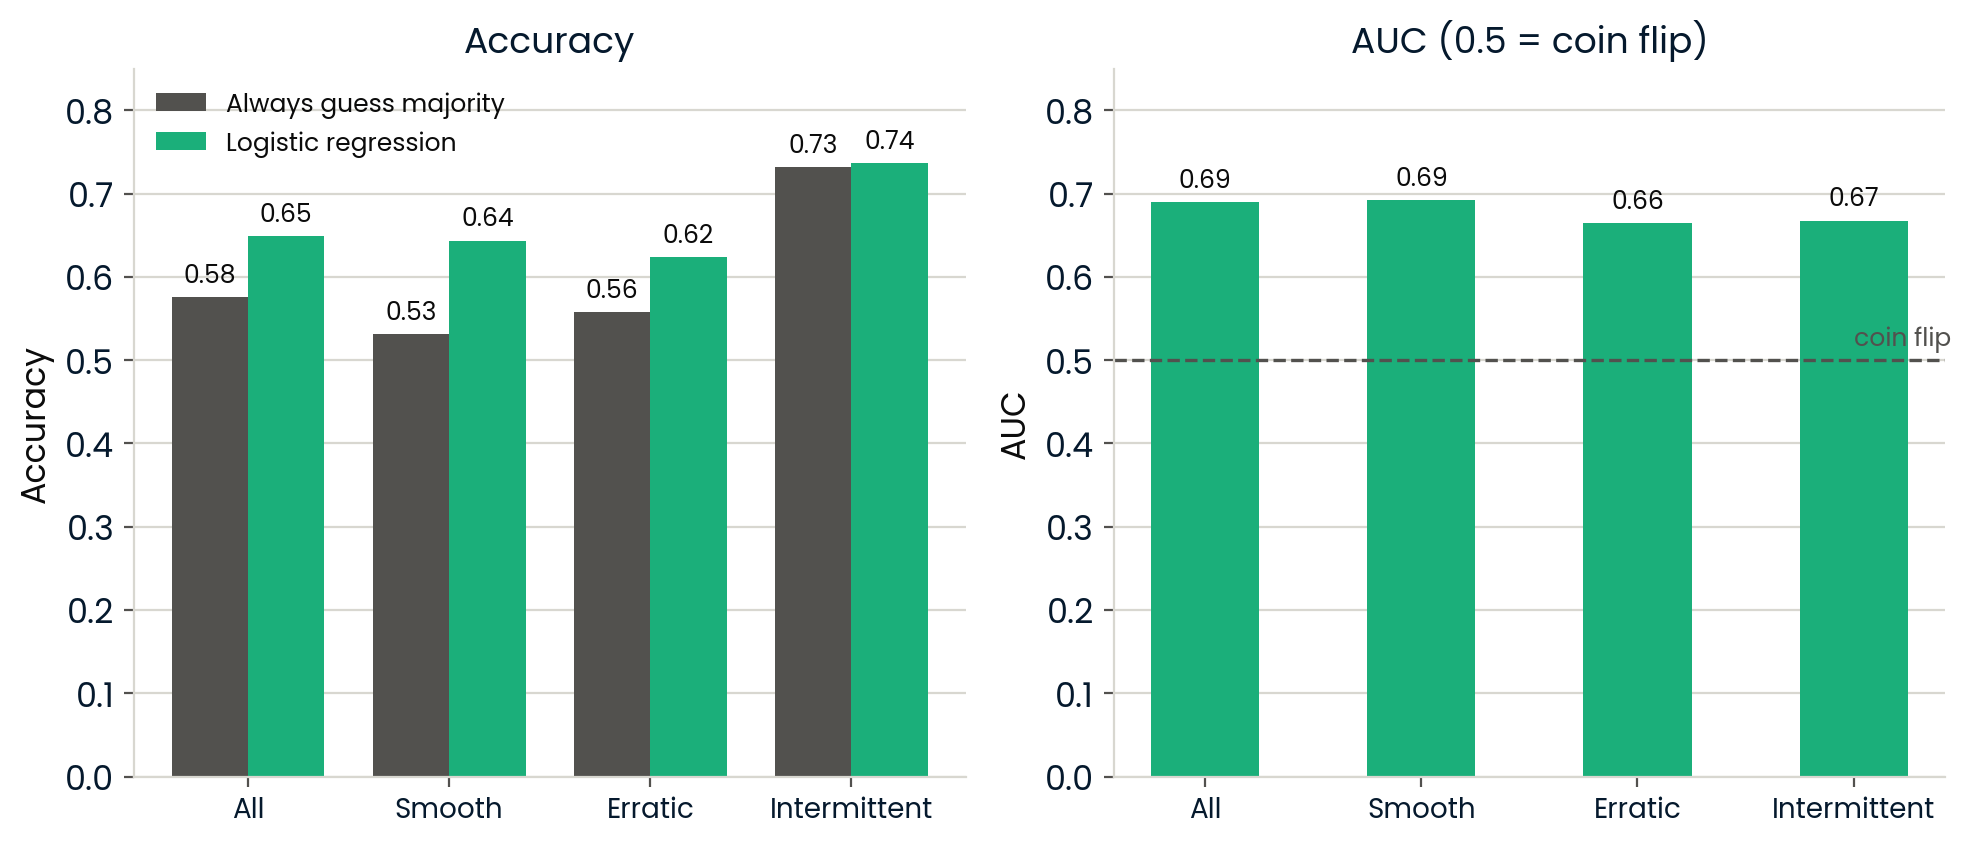

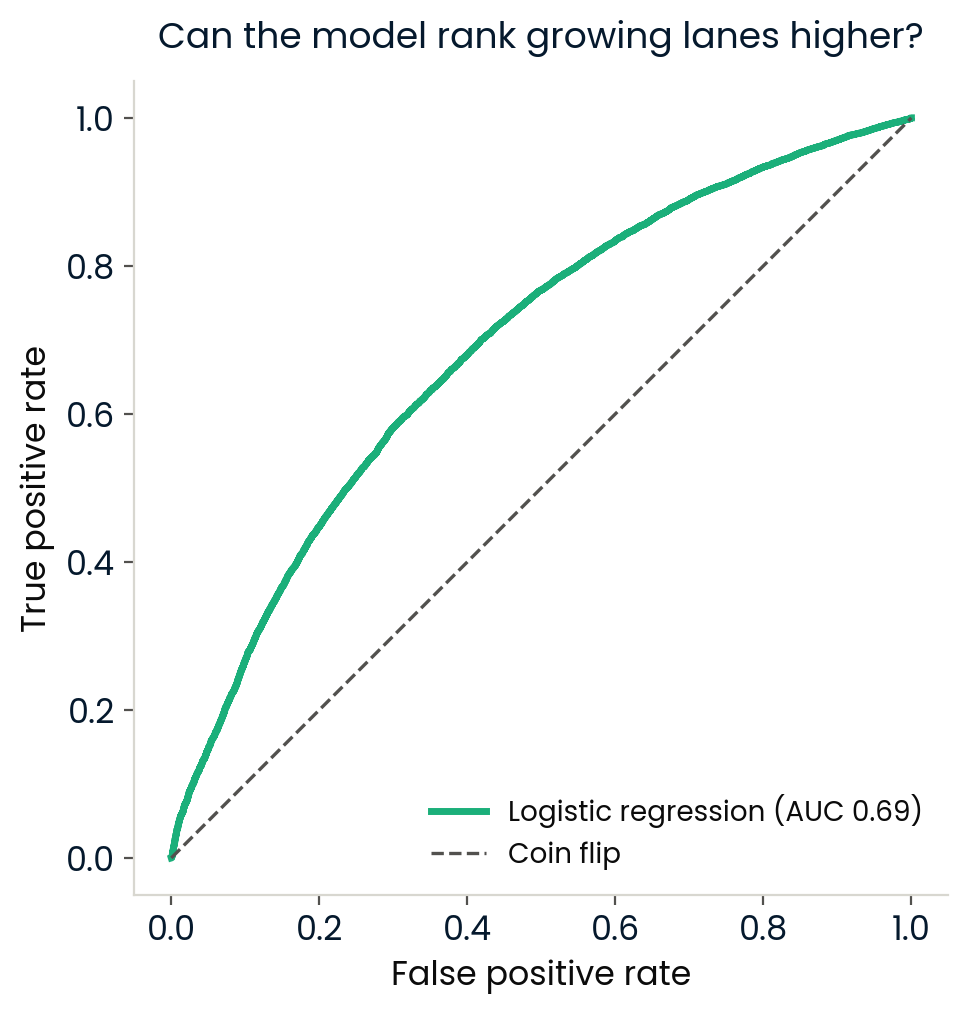

In [2]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve
from eval_utils import *

if os.path.exists("results_classification.csv"):
    os.remove("results_classification.csv")                 # fresh classification table
BLUE, ORANGE, AQUA, MUTED, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#0b0b0b", "#d8d7d0"
plt.rcParams.update({"font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})

panel, seg = load_data(), load_segments()
long = build_features(panel, seg)

# ---- B1: LINEAR REGRESSION - predict this month's TEUs from the past ----
feats = ["lag1", "lag2", "lag3", "roll3", "roll6", "lane_mean"]
train, test = split(long, feats + ["y"])
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}")

pred = pd.Series(index=test.index, dtype=float)
coefs = {}
for s in SEGMENTS:                                          # one model per lane group
    tr, te = train[train.segment == s], test[test.segment == s]
    m = LinearRegression().fit(tr[feats], tr["y"])
    pred[te.index] = m.predict(te[feats])
    coefs[s] = pd.Series(m.coef_, index=feats)
pred_lin = to_panel(test, pred.values)
res = record("Linear regression", pred_lin, panel, seg)
print("\nLinear regression coefficients:")
print(pd.DataFrame(coefs).round(3))
print("\nRegression results (quarterly, 2025):")
print(res.round(2).to_string())

# ---- B2: LOGISTIC REGRESSION - will the lane grow vs. last month? ----
# Only lane-months where the lane shipped last month (lag1 > 0).
# Inputs are divided by the lane's average so big and small lanes are comparable.
for c in ["lag1", "lag2", "lag3", "roll3", "roll6"]:
    long[c + "_rel"] = long[c] / long["lane_mean"]
cfeats = [c + "_rel" for c in ["lag1", "lag2", "lag3", "roll3", "roll6"]]
ctrain, ctest = split(long[long["lag1"] > 0], cfeats)

proba = pd.Series(index=ctest.index, dtype=float)
for s in SEGMENTS:
    tr, te = ctrain[ctrain.segment == s], ctest[ctest.segment == s]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr[cfeats], tr["grew"])
    proba[te.index] = clf.predict_proba(te[cfeats])[:, 1]
clf_res = record_clf("Logistic regression", ctest, proba.values)
print("\nLogistic regression (predict growth vs. last month, 2025 lane-months):")
print(clf_res.round(3).to_string())

# ---- FIGURES ----
x = np.arange(len(SEGMENTS)); w = 0.27
# B1: error by lane group - baseline, SARIMA, linear regression
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, nm in enumerate(["Naive: last month", "SARIMA", "Linear regression"]):
    vals = [res.loc[nm, f"WAPE_{s}"] for s in SEGMENTS]
    bars = ax.bar(x + (i - 1) * w, vals, w, color=COLORS[nm], label=nm)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.8, f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEGMENTS)
ax.set_ylabel("Quarterly WAPE, 2025 (lower = better)")
ax.set_title("Linear regression does not beat 'last month'", fontsize=13, pad=12)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figB1_regression_by_group.png", dpi=150); plt.show()

# B2: predicted vs actual monthly TEUs
act = test["y"].values; prd = np.clip(pred.values, 0, None)
cap = np.percentile(act, 99); mk = act <= cap
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(act[mk], prd[mk], s=6, alpha=0.25, color=COLORS["Linear regression"], edgecolors="none")
ax.plot([0, cap], [0, cap], color=MUTED, linewidth=1.5, linestyle="--", label="Perfect prediction")
ax.set_xlim(0, cap); ax.set_ylim(0, cap); ax.set_aspect("equal")
ax.set_xlabel("Actual TEUs (month)"); ax.set_ylabel("Predicted TEUs (month)")
ax.set_title("Linear regression: predicted vs. actual\n(2025 months, 99th percentile and below)", fontsize=13, pad=12)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figB2_linear_pred_vs_actual.png", dpi=150); plt.show()

# B3: logistic - accuracy vs majority guess, and AUC, by lane group
groups = ["All"] + SEGMENTS
xx = np.arange(len(groups)); w2 = 0.38
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.4))
b1 = a1.bar(xx - w2/2, clf_res.loc[groups, "majority_baseline"], w2, color=MUTED, label="Always guess majority")
b2 = a1.bar(xx + w2/2, clf_res.loc[groups, "accuracy"], w2, color=COLORS["Linear regression"], label="Logistic regression")
for bars in (b1, b2):
    for b in bars:
        a1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
a1.set_xticks(xx); a1.set_xticklabels(groups, fontsize=10); a1.set_ylim(0, 0.85)
a1.set_ylabel("Accuracy"); a1.set_title("Accuracy", fontsize=13)
a1.legend(frameon=False, loc="upper left", fontsize=9)
bars = a2.bar(xx, clf_res.loc[groups, "AUC"], 0.5, color=COLORS["Linear regression"])
for b in bars:
    a2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
a2.axhline(0.5, color=MUTED, linestyle="--", linewidth=1.2)
a2.text(len(groups) - 0.55, 0.51, "coin flip", color=MUTED, ha="right", va="bottom", fontsize=9)
a2.set_xticks(xx); a2.set_xticklabels(groups, fontsize=10); a2.set_ylim(0, 0.85)
a2.set_ylabel("AUC"); a2.set_title("AUC (0.5 = coin flip)", fontsize=13)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
    a.yaxis.grid(True, color=GRID, linewidth=0.8); a.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figB3_logistic_by_group.png", dpi=150); plt.show()

# B4: ROC curve, all lane-months
fpr, tpr, _ = roc_curve(ctest["grew"], proba[ctest.index])
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot(fpr, tpr, color=COLORS["Linear regression"], linewidth=2.5, label=f"Logistic regression (AUC {clf_res.loc['All','AUC']:.2f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Coin flip")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_aspect("equal")
ax.set_title("Can the model rank growing lanes higher?", fontsize=13, pad=12)
ax.legend(frameon=False, loc="lower right", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figB4_logistic_roc.png", dpi=150); plt.show()

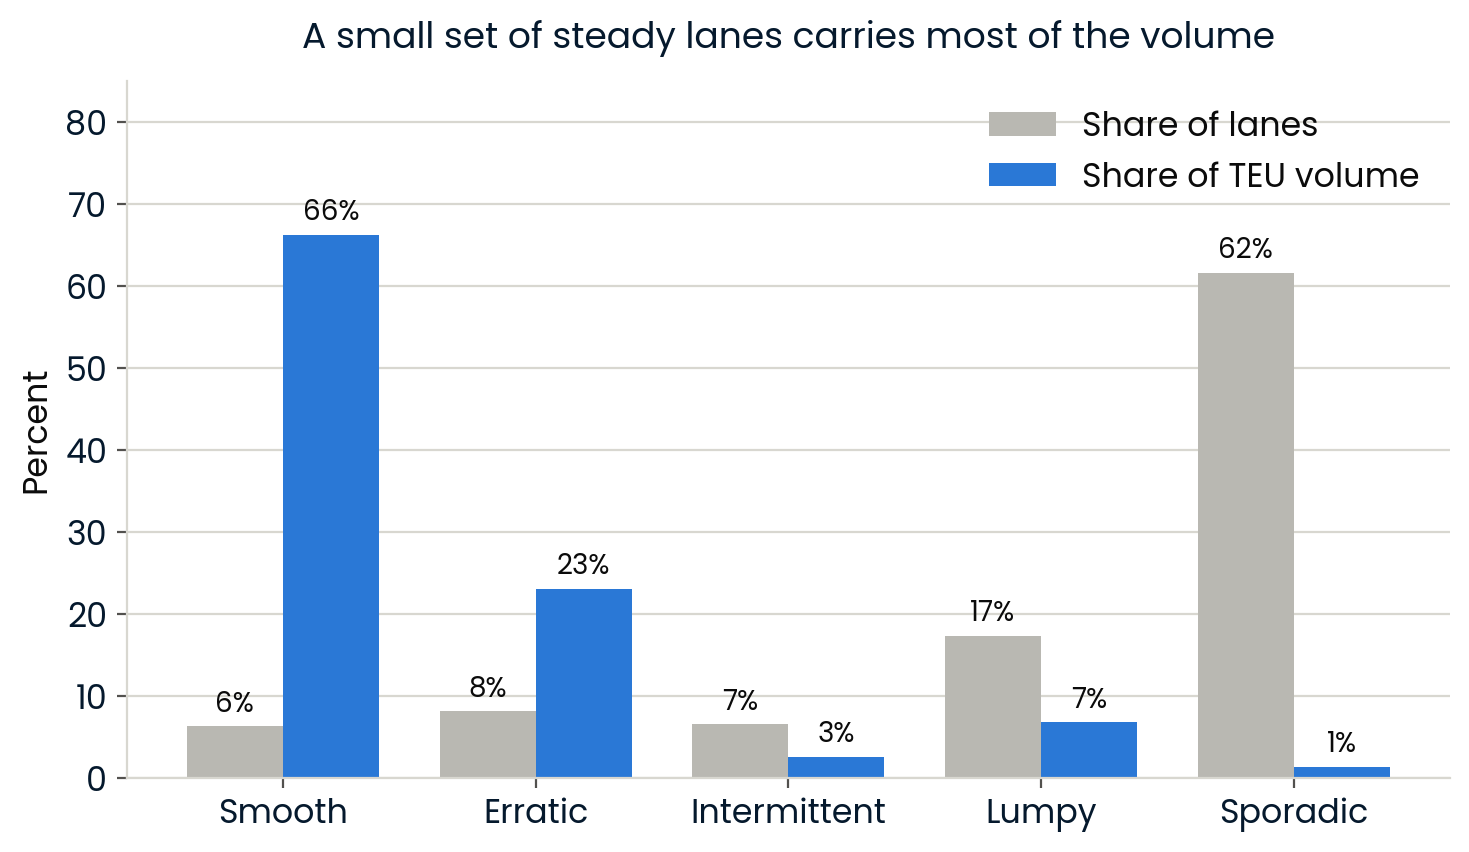

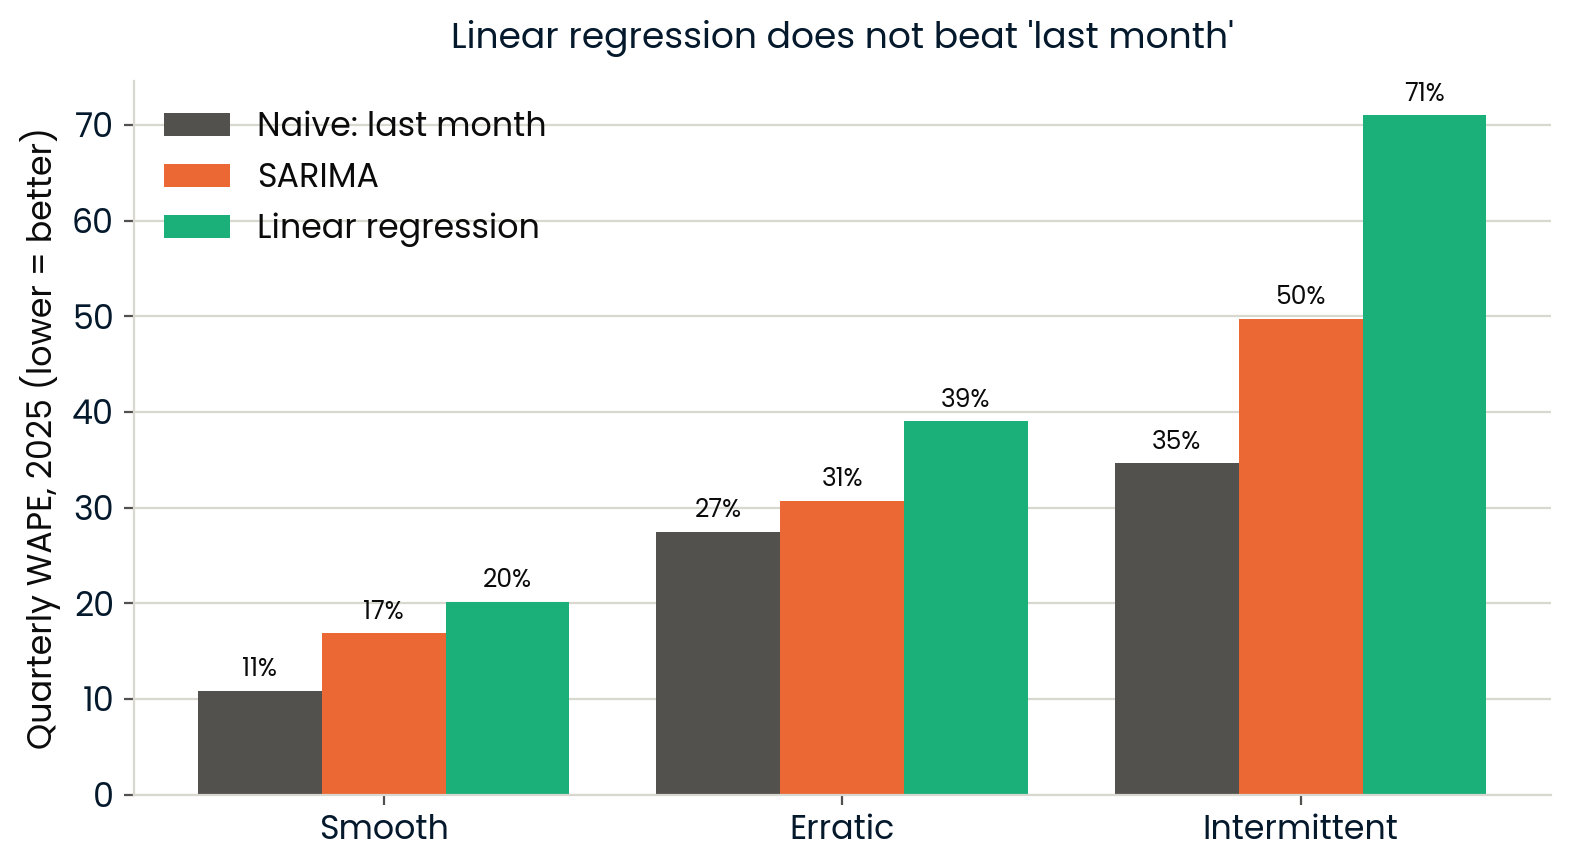

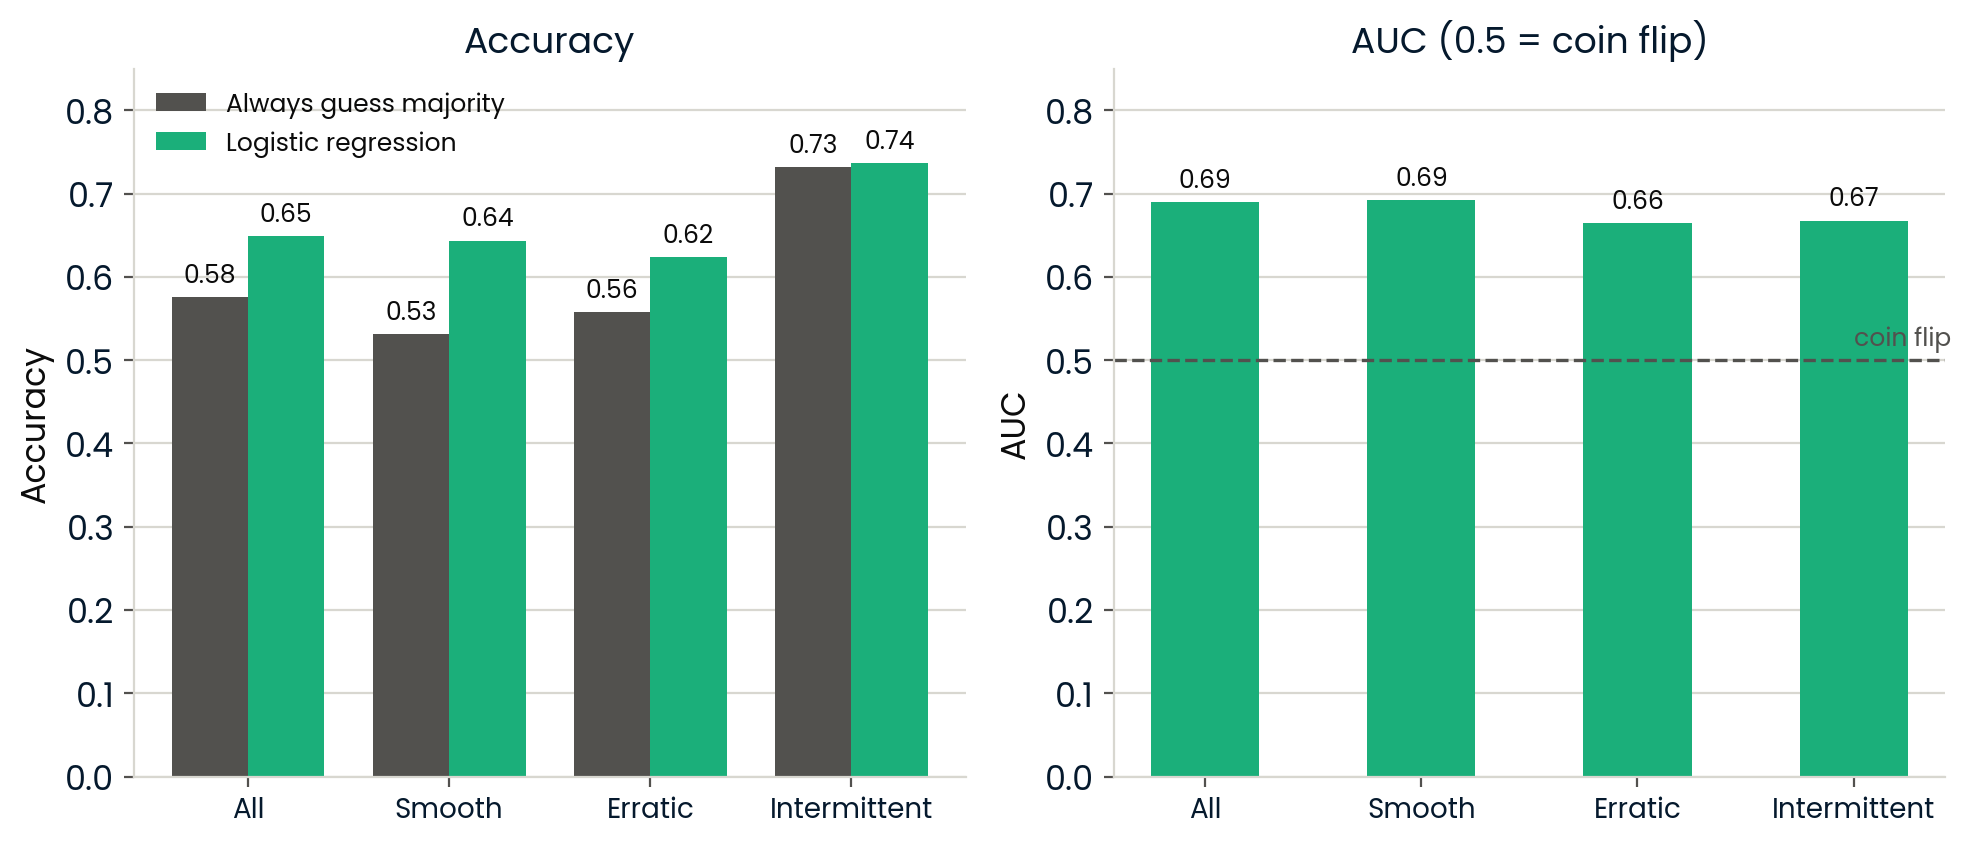

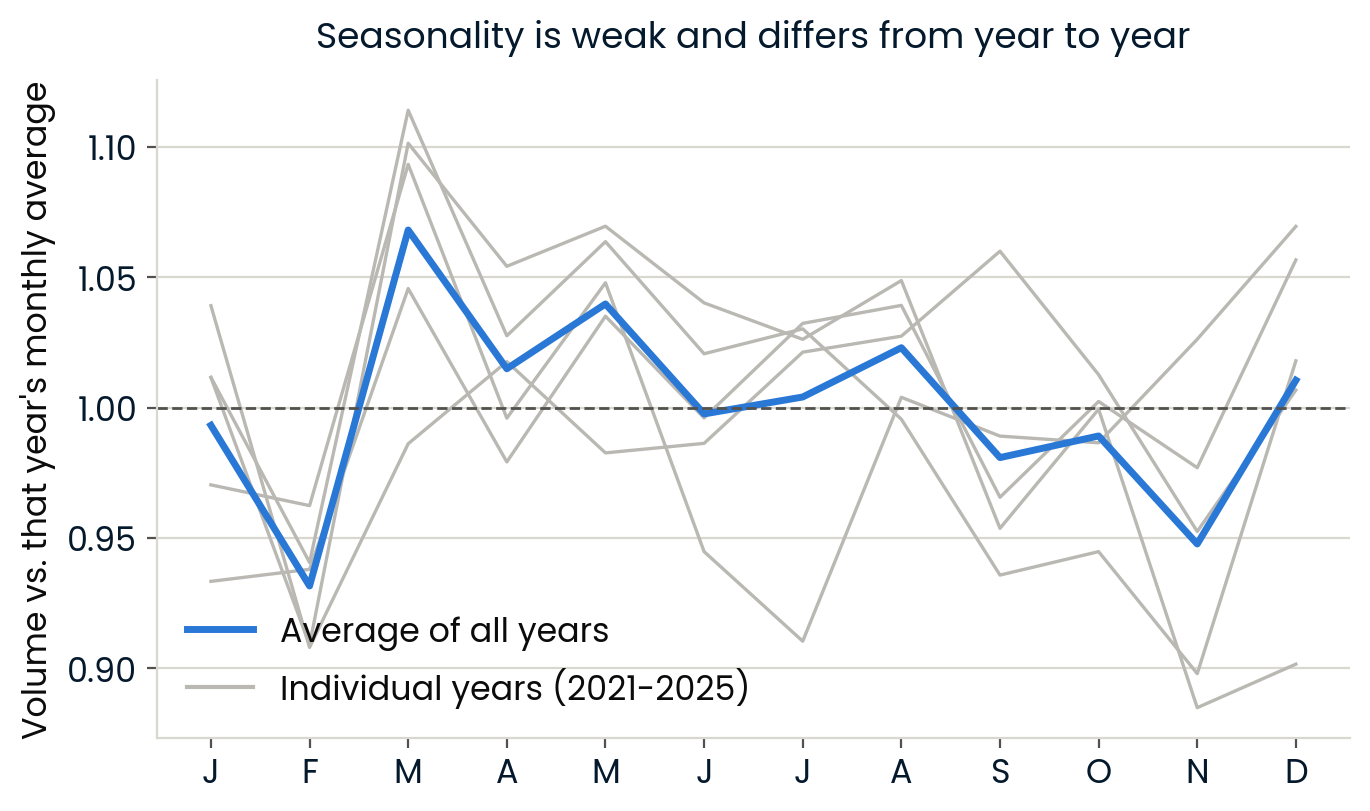

Saved 4 figures: report_fig1 to report_fig4


In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BLUE, MUTED, INK, GRID, GRAY = "#2a78d6", "#52514e", "#0b0b0b", "#d8d7d0", "#b9b8b2"
COLORS = {"Naive: last month": "#52514e", "SARIMA": "#eb6834", "Linear regression": "#1baf7a"}
SEGMENTS = ["Smooth", "Erratic", "Intermittent"]
plt.rcParams.update({"font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})
DPI = 300

# ---------------- Figure 1: share of lanes vs share of volume ----------------
panel = pd.read_pickle("monthly_panel.pkl")
seg_all = pd.read_pickle("lane_segments.pkl")
train_vol = panel.loc[:, :"2024-12-01"].sum(axis=1)
ORDER = ["Smooth", "Erratic", "Intermittent", "Lumpy", "Sporadic"]
summ = pd.DataFrame({"lanes": seg_all.value_counts(), "volume": train_vol.groupby(seg_all).sum()}).loc[ORDER]
summ["pct_lanes"] = summ["lanes"] / summ["lanes"].sum() * 100
summ["pct_volume"] = summ["volume"] / summ["volume"].sum() * 100

x = np.arange(len(ORDER)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.4))
b1 = ax.bar(x - w/2, summ["pct_lanes"], w, color=GRAY, label="Share of lanes")
b2 = ax.bar(x + w/2, summ["pct_volume"], w, color=BLUE, label="Share of TEU volume")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.0f}%", ha="center", va="bottom", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(ORDER)
ax.set_ylim(0, 85); ax.set_ylabel("Percent")
ax.set_title("A small set of steady lanes carries most of the volume", fontsize=13, pad=12)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("report_fig1_lane_groups.png", dpi=DPI); plt.show()

# ---------------- Figure 2: error by lane group (baseline, SARIMA, linear) ----------------
res = pd.read_csv("results_all.csv", index_col="model")
x = np.arange(len(SEGMENTS)); w = 0.27
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, nm in enumerate(["Naive: last month", "SARIMA", "Linear regression"]):
    vals = [res.loc[nm, f"WAPE_{s}"] for s in SEGMENTS]
    bars = ax.bar(x + (i - 1) * w, vals, w, color=COLORS[nm], label=nm)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.8, f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEGMENTS)
ax.set_ylabel("Quarterly WAPE, 2025 (lower = better)")
ax.set_title("Linear regression does not beat 'last month'", fontsize=13, pad=12)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("report_fig2_model_error_by_group.png", dpi=DPI); plt.show()

# ---------------- Figure 3: logistic regression, accuracy and AUC ----------------
c = pd.read_csv("results_classification.csv")
c = c[c["model"] == "Logistic regression"].set_index("group")
groups = ["All"] + SEGMENTS
xx = np.arange(len(groups)); w2 = 0.38
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.4))
b1 = a1.bar(xx - w2/2, c.loc[groups, "majority_baseline"], w2, color=MUTED, label="Always guess majority")
b2 = a1.bar(xx + w2/2, c.loc[groups, "accuracy"], w2, color=COLORS["Linear regression"], label="Logistic regression")
for bars in (b1, b2):
    for b in bars:
        a1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
a1.set_xticks(xx); a1.set_xticklabels(groups, fontsize=10); a1.set_ylim(0, 0.85)
a1.set_ylabel("Accuracy"); a1.set_title("Accuracy", fontsize=13)
a1.legend(frameon=False, loc="upper left", fontsize=9)
bars = a2.bar(xx, c.loc[groups, "AUC"], 0.5, color=COLORS["Linear regression"])
for b in bars:
    a2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
a2.axhline(0.5, color=MUTED, linestyle="--", linewidth=1.2)
a2.text(len(groups) - 0.55, 0.51, "coin flip", color=MUTED, ha="right", va="bottom", fontsize=9)
a2.set_xticks(xx); a2.set_xticklabels(groups, fontsize=10); a2.set_ylim(0, 0.85)
a2.set_ylabel("AUC"); a2.set_title("AUC (0.5 = coin flip)", fontsize=13)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
    a.yaxis.grid(True, color=GRID, linewidth=0.8); a.set_axisbelow(True)
plt.tight_layout(); plt.savefig("report_fig3_logistic_results.png", dpi=DPI); plt.show()

# ---------------- Figure 4: seasonality (final modeling lanes) ----------------
model_panel = pd.read_pickle("modeling_panel.pkl")
total = model_panel.sum()
fig, ax = plt.subplots(figsize=(7, 4.2))
profiles = []
for yr, s_ in total.groupby(total.index.year):
    idx = (s_ / s_.mean()).values
    profiles.append(idx)
    ax.plot(range(1, 13), idx, color=GRAY, linewidth=1.2)
ax.plot(range(1, 13), np.mean(profiles, axis=0), color=BLUE, linewidth=2.5, label="Average of all years")
ax.plot([], [], color=GRAY, label="Individual years (2021-2025)")
ax.axhline(1, color=MUTED, linestyle="--", linewidth=1)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("Volume vs. that year's monthly average")
ax.set_title("Seasonality is weak and differs from year to year", fontsize=13, pad=12)
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("report_fig4_seasonality.png", dpi=DPI); plt.show()

print("Saved 4 figures: report_fig1 to report_fig4")